# Lecture 18

Today's Topics:

- From Predicting to Generating
- Autoencoders
- A 2D Latent Space
- Generating from the Latent Space (and Where It Breaks)
- Variational Autoencoders (VAEs)
- Sampling New Images
- Interpolation
- Denoising Autoencoders

In [ ]:
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split

import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

In [2]:
# Device-agnostic code: use the GPU if there is one, otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

## From Predicting to Generating

Every model so far has been **supervised**: we gave it inputs *and* labels, and it learned to predict the label. Given an image, output "sneaker".

A **generative model** goes the other way: it learns what the data itself looks like, well enough to produce **new examples** that could plausibly have come from the dataset. That's what image generators and chatbots do.

Today we'll build up to a generative model in two steps:

1. **Autoencoders**, which learn to compress an image into a few numbers and rebuild it. They need no labels at all.
2. **Variational autoencoders (VAEs)**, a small change to autoencoders that lets us generate brand-new images.

We'll use FashionMNIST again, so we can focus on the new ideas.

In [ ]:
train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=ToTensor())
class_names = train_data.classes

train_split, val_split = random_split(train_data, [50_000, 10_000],
                                      generator=torch.Generator().manual_seed(42))

BATCH_SIZE = 128
train_dataloader = DataLoader(train_split, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(val_split, batch_size=BATCH_SIZE, shuffle=False)

len(train_split), len(val_split)

(50000, 10000)

We'll still load the labels, because they're useful for *coloring plots*. But notice as we go: **none of today's models will ever see a label during training**.

## Autoencoders

An **autoencoder** is a network trained to output its own input. That sounds pointless, until you squeeze the data through a narrow middle layer:

- The **encoder** compresses a 784-pixel image into a short vector, called the **latent code** (or just "code"). The space of all possible codes is the **latent space**.
- The **decoder** takes the code and tries to rebuild the original 784 pixels.

Because the code is much smaller than the image, the network can't just copy pixels through. It has to learn a compact description of what makes one piece of clothing different from another.

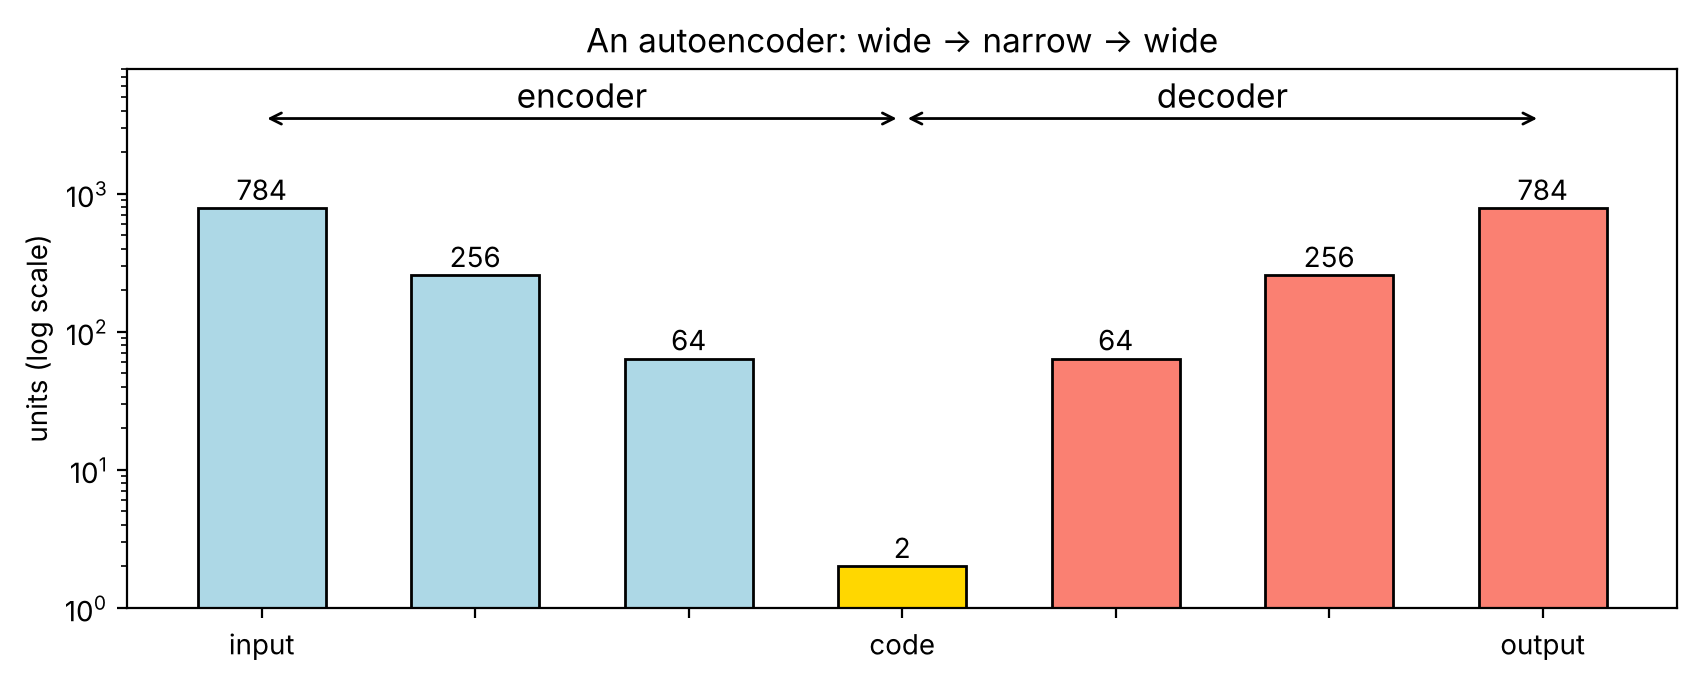

In [4]:
layer_sizes = [784, 256, 64, 2, 64, 256, 784]
labels = ["input", "", "", "code", "", "", "output"]
colors = ["lightblue"] * 3 + ["gold"] + ["salmon"] * 3

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(layer_sizes)), layer_sizes, color=colors, edgecolor="black", width=0.6)
ax.set_yscale("log")
for i, n in enumerate(layer_sizes):
    ax.text(i, n * 1.15, str(n), ha="center", fontsize=10)
ax.set_xticks(range(len(layer_sizes)), labels)
ax.set_ylabel("units (log scale)")
ax.set_ylim(1, 8000)
ax.annotate("", xy=(0, 3500), xytext=(3, 3500), arrowprops=dict(arrowstyle="<->"))
ax.annotate("", xy=(3, 3500), xytext=(6, 3500), arrowprops=dict(arrowstyle="<->"))
ax.text(1.5, 4200, "encoder", ha="center", fontsize=12)
ax.text(4.5, 4200, "decoder", ha="center", fontsize=12)
ax.set_title("An autoencoder: wide -> narrow -> wide")
plt.show()

We build the encoder and decoder as two separate `nn.Sequential` blocks, so we can use each one on its own later.

Two details about the decoder's output:

- It ends with `nn.Sigmoid()`, which squashes every output into $[0, 1]$. In Lecture 16 we said "no activation after the output layer", but that was for *logits* going into `nn.CrossEntropyLoss()`. Here the outputs are **pixel brightnesses**, which really are between 0 and 1.
- `nn.Unflatten()` reshapes the 784 outputs back into a $1 \times 28 \times 28$ image, the reverse of `nn.Flatten()`.

In [5]:
def make_encoder(out_features: int):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 256),
        nn.ReLU(),
        nn.Linear(256, 64),
        nn.ReLU(),
        nn.Linear(64, out_features)
    )


def make_decoder(latent_dim: int):
    return nn.Sequential(
        nn.Linear(latent_dim, 64),
        nn.ReLU(),
        nn.Linear(64, 256),
        nn.ReLU(),
        nn.Linear(256, 784),
        nn.Sigmoid(),                 # pixel values between 0 and 1
        nn.Unflatten(1, (1, 28, 28))  # 784 -> 1 x 28 x 28
    )


class Autoencoder(nn.Module):
    def __init__(self, latent_dim: int):
        super().__init__()
        self.encoder = make_encoder(latent_dim)
        self.decoder = make_decoder(latent_dim)

    def forward(self, x):
        z = self.encoder(x)      # compress
        return self.decoder(z)   # rebuild

### The loss: how well did we rebuild the image?

There's no label, so the loss compares the output with the **input itself**. This is called the **reconstruction loss**. We'll use **binary cross-entropy (BCE)** on each pixel, treating each pixel's brightness like a probability between 0 and 1. (Mean squared error also works; BCE tends to train a little faster for images like these.)

We sum the loss over the 784 pixels and average over the images in the batch, so the number we see is "reconstruction error per image".

Our loss functions take the model and a batch, and return the loss plus a dictionary of numbers to log. That way the same training loop works for every model today.

In [6]:
def reconstruction_loss(X_hat, X):
    # Binary cross-entropy summed over pixels, averaged over the batch
    return F.binary_cross_entropy(X_hat, X, reduction="sum") / len(X)


def autoencoder_loss(model, X):
    X_hat = model(X)
    loss = reconstruction_loss(X_hat, X)
    return loss, {"recon": loss.item()}

### Training loop

We will be using our `fit()` function from Lecture 16 with two changes: the labels `y` are ignored, and the loss comes from the `loss_fn(model, X)` functions above. It records every number the loss function logs, for both training and validation.

In [7]:
def train_step(model, data_loader, loss_fn, optimizer, device=device):
    model.to(device)
    model.train()
    totals = {}
    for X, _ in data_loader:          # labels are ignored!
        X = X.to(device)
        loss, logs = loss_fn(model, X)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        for k, v in logs.items():
            totals[k] = totals.get(k, 0) + v
    return {k: v / len(data_loader) for k, v in totals.items()}


def eval_step(model, data_loader, loss_fn, device=device):
    model.to(device)
    model.eval()
    totals = {}
    with torch.inference_mode():
        for X, _ in data_loader:
            X = X.to(device)
            _, logs = loss_fn(model, X)
            for k, v in logs.items():
                totals[k] = totals.get(k, 0) + v
    return {k: v / len(data_loader) for k, v in totals.items()}


def fit(model, train_dataloader, val_dataloader, loss_fn, optimizer, epochs, print_every=1):
    history = {}
    for epoch in range(epochs):
        train_logs = train_step(model, train_dataloader, loss_fn, optimizer)
        val_logs = eval_step(model, val_dataloader, loss_fn)
        for k in train_logs:
            history.setdefault(f"train_{k}", []).append(train_logs[k])
            history.setdefault(f"val_{k}", []).append(val_logs[k])
        if epoch % print_every == 0 or epoch == epochs - 1:
            msg = " | ".join(f"{k}: train {train_logs[k]:.2f}, val {val_logs[k]:.2f}" for k in train_logs)
            print(f"Epoch {epoch:2d} | {msg}")
    return history


def plot_losses(histories: dict, key="recon", title=""):
    plt.figure(figsize=(7, 4))
    for i, (name, h) in enumerate(histories.items()):
        epochs = range(1, len(h[f"train_{key}"]) + 1)
        plt.plot(epochs, h[f"train_{key}"], "--", color=f"C{i}", label=f"{name} (train)")
        plt.plot(epochs, h[f"val_{key}"], "-", color=f"C{i}", label=f"{name} (val)")
    plt.xlabel("Epoch")
    plt.ylabel(f"{key} loss per image")
    plt.title(title)
    plt.legend()
    plt.show()

## A 2D Latent Space

Let's start with an extreme bottleneck: a code of just **2 numbers**. Compressing a 784-pixel image into 2 numbers loses a lot, but it means we can **plot** every image's code as a point.

This is the same 784 $\to$ 2 squeeze as the tiny model from Lecture 16, which underfit badly as a *classifier*. Here we'll see what it learns when it doesn't have to predict labels.

In [8]:
torch.manual_seed(42)
ae_2d = Autoencoder(latent_dim=2).to(device)
optimizer = torch.optim.Adam(ae_2d.parameters(), lr=0.001)

start = time.time()
ae_2d_history = fit(ae_2d, train_dataloader, val_dataloader, autoencoder_loss, optimizer, epochs=15)
print(f"\nTraining time: {(time.time() - start) / 60:.1f} min")

Epoch  0 | recon: train 291.11, val 262.29


Epoch  1 | recon: train 260.05, val 258.87


Epoch  2 | recon: train 257.47, val 257.21


Epoch  3 | recon: train 256.01, val 255.94


Epoch  4 | recon: train 254.99, val 255.27


Epoch  5 | recon: train 254.01, val 254.18


... (5 outputs left out)

Epoch 11 | recon: train 250.69, val 251.56


Epoch 12 | recon: train 250.31, val 251.19


Epoch 13 | recon: train 249.97, val 250.97


Epoch 14 | recon: train 249.75, val 250.44

Training time: 1.3 min


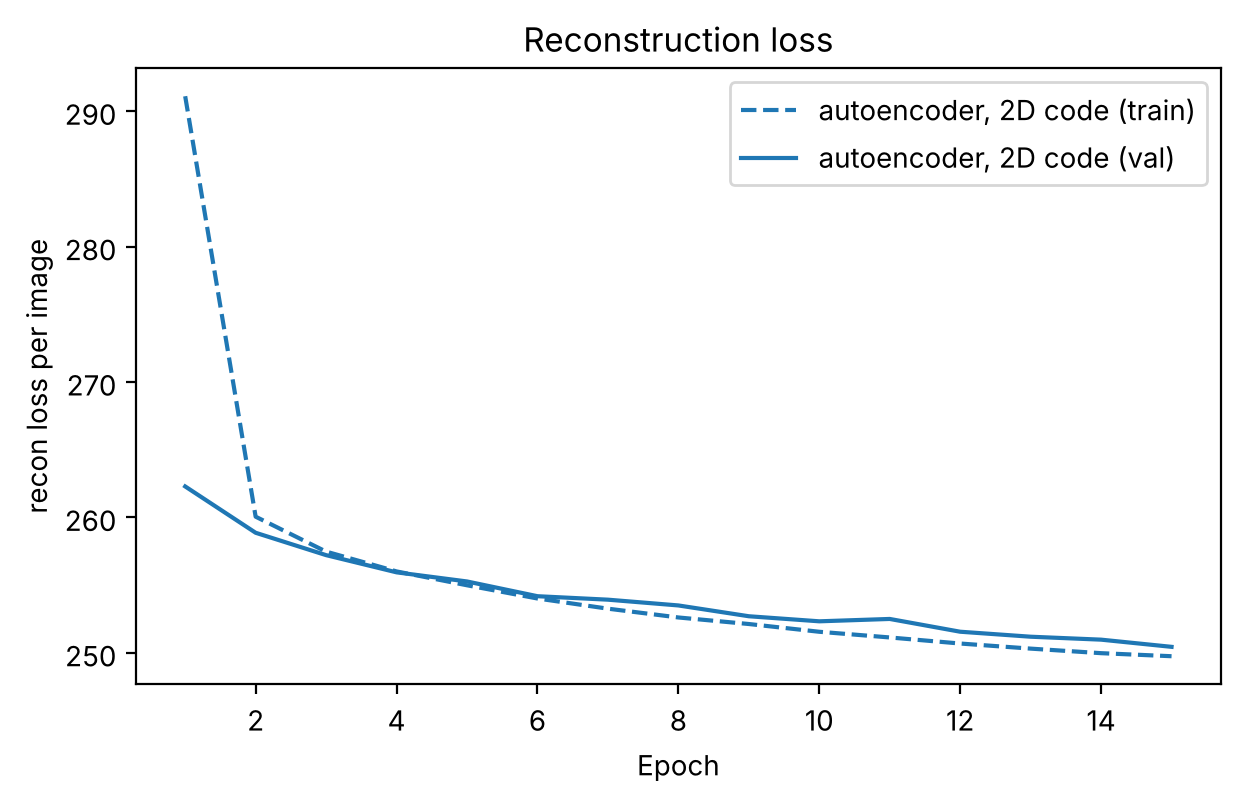

In [9]:
plot_losses({"autoencoder, 2D code": ae_2d_history}, title="Reconstruction loss")

### Reconstructions

The loss number is hard to interpret on its own. Let's look at some validation images next to their reconstructions:

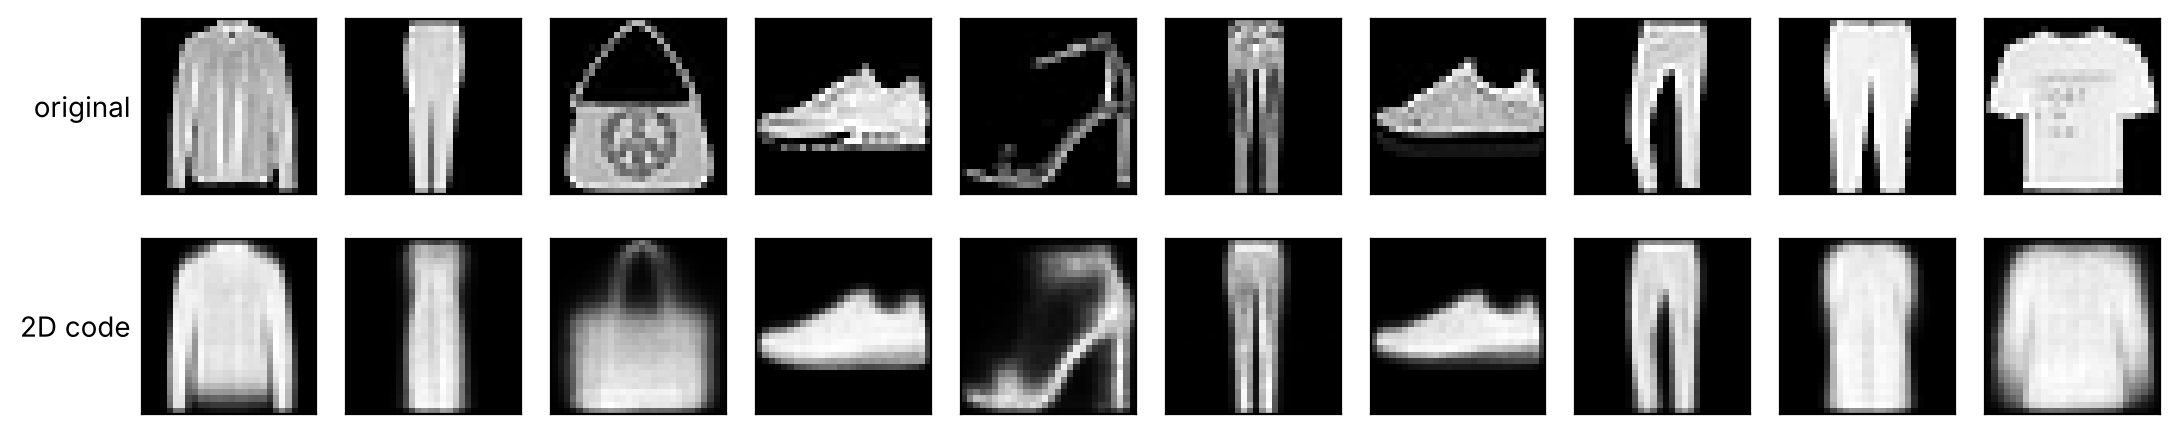

In [10]:
X_val, y_val = next(iter(val_dataloader))   # one batch of validation images
X_val = X_val.to(device)


def show_reconstructions(models: dict, X, n=10):
    # Row 1: originals; one row per model: reconstructions
    rows = 1 + len(models)
    fig, axes = plt.subplots(rows, n, figsize=(n * 1.1, rows * 1.25))
    outputs = {}
    for name, model in models.items():
        model.eval()
        with torch.inference_mode():
            out = model(X[:n])
            outputs[name] = out[0] if isinstance(out, tuple) else out   # VAEs return a tuple
    for j in range(n):
        axes[0, j].imshow(X[j].squeeze().cpu(), cmap="gray")
        for r, name in enumerate(models, start=1):
            axes[r, j].imshow(outputs[name][j].squeeze().cpu(), cmap="gray")
    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
    axes[0, 0].set_ylabel("original", rotation=0, ha="right", va="center")
    for r, name in enumerate(models, start=1):
        axes[r, 0].set_ylabel(name, rotation=0, ha="right", va="center")
    plt.tight_layout()
    plt.show()

show_reconstructions({"2D code": ae_2d}, X_val)

Two numbers are enough to keep **what kind of item** it is and its rough **shape**: the trousers, sneakers and long-sleeved top come back clearly. Everything else is lost. The bag loses its print, the top loses its stripes, the T-shirt comes back as a vague top, and the strappy sandal turns into a blurry generic high heel.

The reconstructions are also **blurry**. When the decoder can't tell exactly which image a code came from, the safest output (lowest loss) is something like the *average* of all the images that could have had that code, and averages are blurry. We'll see this again and again today.

### The latent space

Now the payoff of a 2D code. We run every validation image through the **encoder only**, and plot its 2 numbers as a point. We color the points by class, but remember that the autoencoder **never saw these labels**.

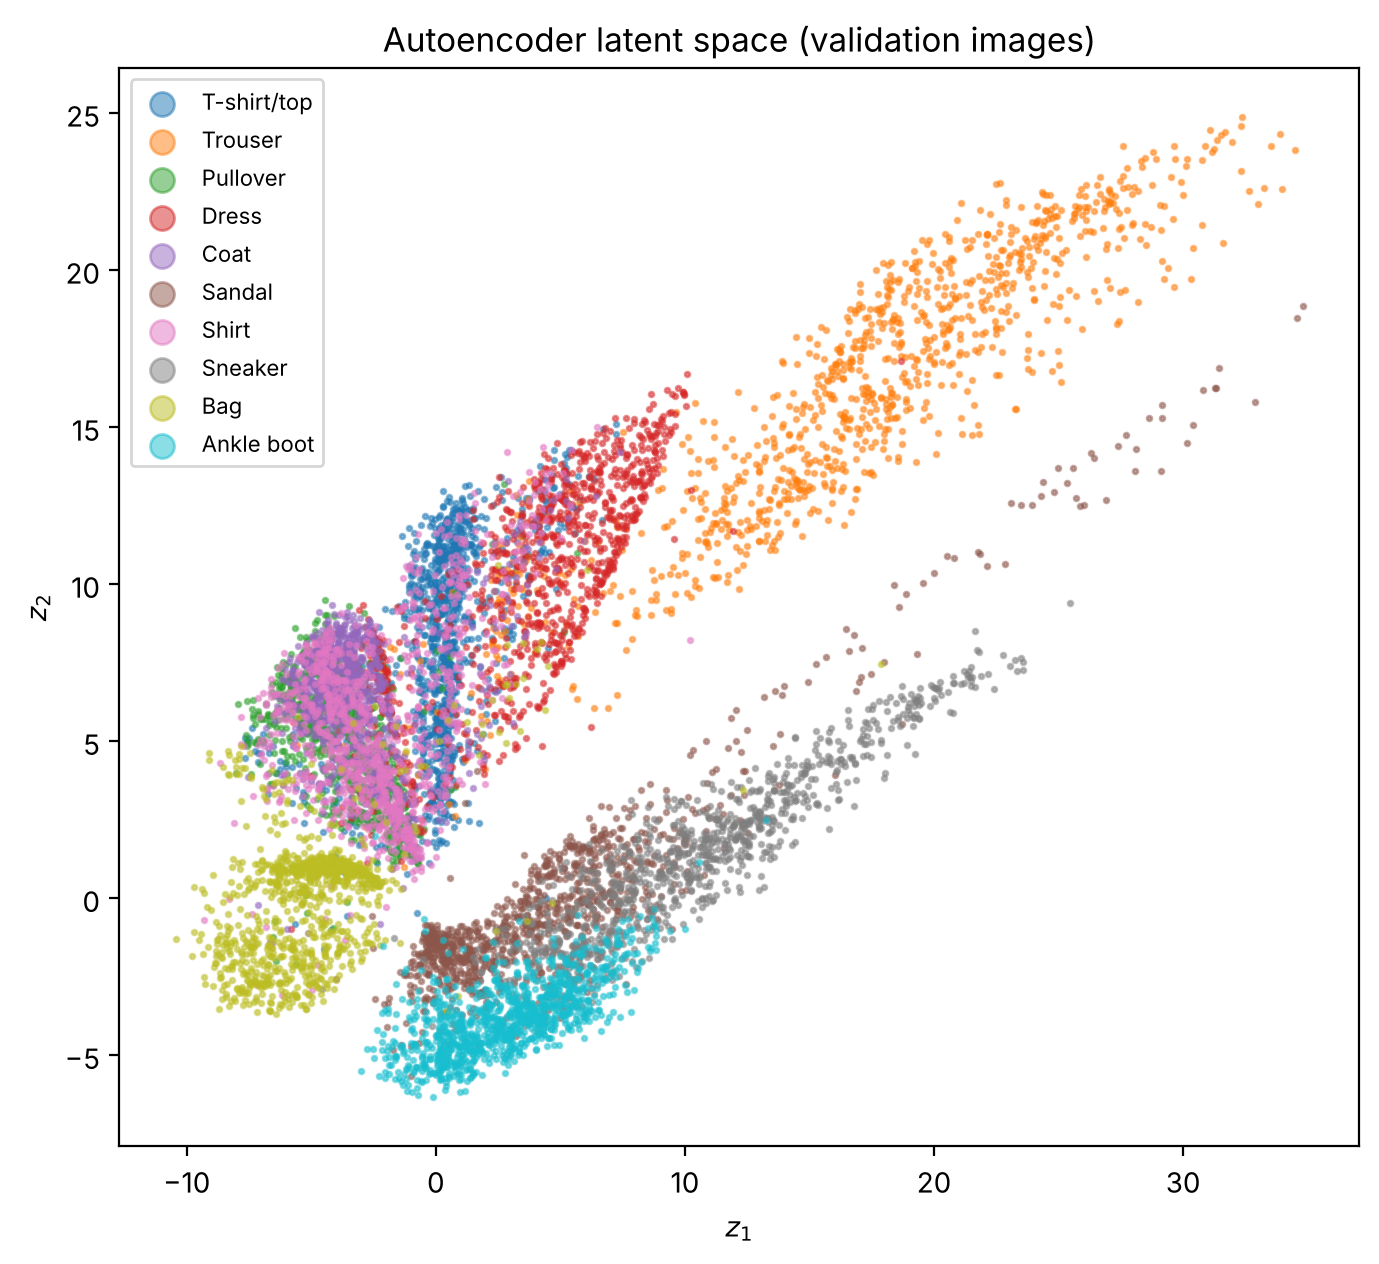

In [11]:
def encode_dataset(encode_fn, data_loader):
    # Returns the latent codes and labels for every image in data_loader
    codes, labels = [], []
    with torch.inference_mode():
        for X, y in data_loader:
            codes.append(encode_fn(X.to(device)).cpu())
            labels.append(y)
    return torch.cat(codes).numpy(), torch.cat(labels).numpy()


def plot_latent(codes, labels, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 7))
    for k, name in enumerate(class_names):
        mask = labels == k
        ax.scatter(codes[mask, 0], codes[mask, 1], s=3, alpha=0.5, color=plt.cm.tab10(k), label=name)
    ax.set_xlabel("$z_1$")
    ax.set_ylabel("$z_2$")
    ax.set_title(title)
    ax.legend(markerscale=5, fontsize=8, loc="best")
    return ax

ae_2d.eval()
ae_codes, val_labels = encode_dataset(ae_2d.encoder, val_dataloader)

plot_latent(ae_codes, val_labels, "Autoencoder latent space (validation images)")
plt.show()

The clothing organizes itself into regions **without any labels**:

- **Trousers** get their own long streak.
- **Footwear** (sandals, sneakers, ankle boots) shares a separate band along the bottom, with the three types next to each other.
- **Bags** sit in their own cluster.
- **Tops** are in the upper left, and the classes that look alike (pullover, coat and shirt) pile on top of each other. These are the same classes our classifiers confused in Lecture 14.

The autoencoder discovered these groups only because similar-looking items need similar codes to be rebuilt well.

Also notice the **shape** of the latent space: long, thin streaks stretching from about $-10$ to $35$, with large empty regions between them, and a sparse trail of sandals. Keep this in mind; it causes problems in a moment.

### More room in the code

A 2-number code is great for plotting but loses a lot of detail. Let's train the same autoencoder with a **16-number** code and compare reconstructions. For reference, we'll also add **PCA** with 2 components, the classic linear way to compress data to 2 numbers. (An autoencoder with no activation functions learns essentially the same thing as PCA; the ReLUs are what let it go further.)

In [12]:
torch.manual_seed(42)
ae_16d = Autoencoder(latent_dim=16).to(device)
optimizer = torch.optim.Adam(ae_16d.parameters(), lr=0.001)
ae_16d_history = fit(ae_16d, train_dataloader, val_dataloader, autoencoder_loss, optimizer,
                     epochs=10, print_every=3)

Epoch  0 | recon: train 285.40, val 246.43


Epoch  3 | recon: train 230.82, val 229.99


Epoch  6 | recon: train 224.61, val 224.61


Epoch  9 | recon: train 221.62, val 221.97


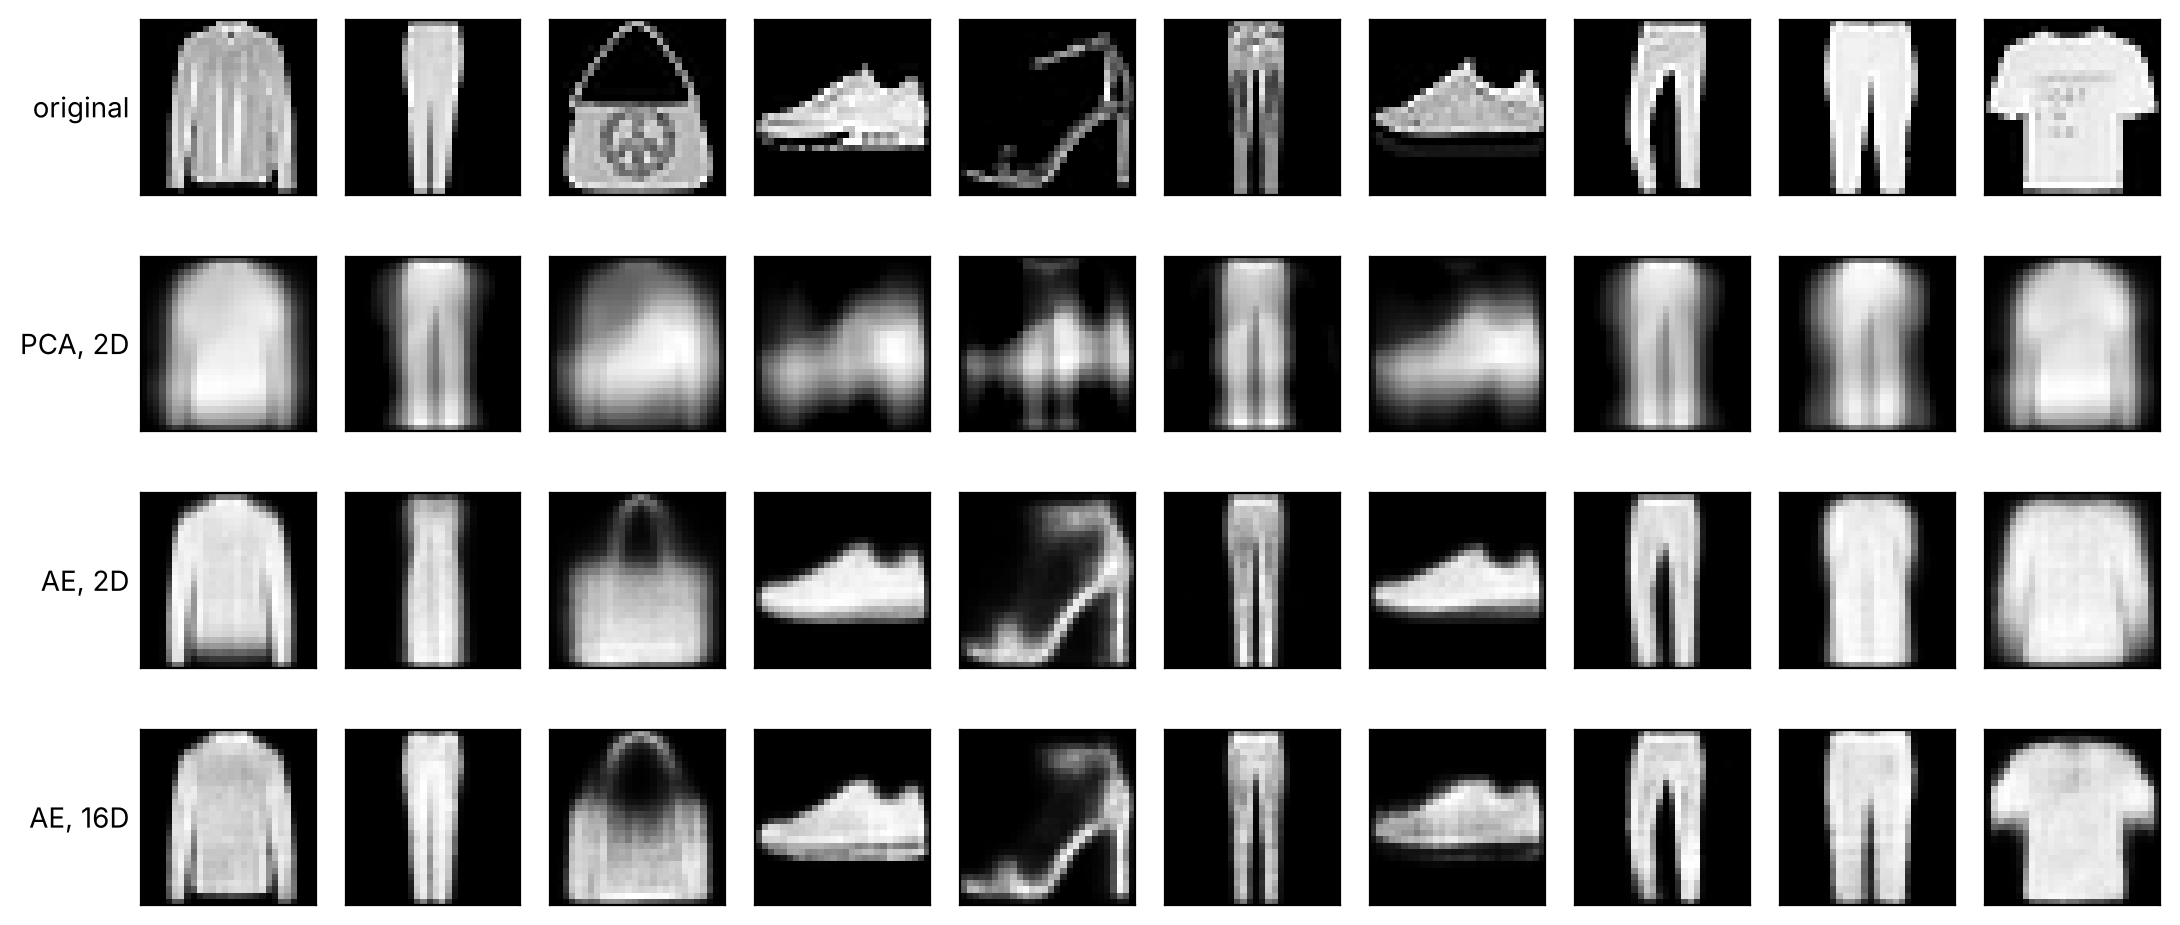

In [13]:
from sklearn.decomposition import PCA

# Fit PCA on (a sample of) the training images, flattened to 784 numbers
X_train_flat = torch.stack([train_split[i][0] for i in range(10_000)]).view(-1, 784).numpy()
pca = PCA(n_components=2).fit(X_train_flat)


class PCAModel(nn.Module):
    # Wraps PCA so it looks like our other models: compress to 2 numbers, then rebuild
    def forward(self, X):
        flat = X.view(len(X), -1).cpu().numpy()
        rebuilt = pca.inverse_transform(pca.transform(flat)).clip(0, 1)
        return torch.tensor(rebuilt, dtype=torch.float32).view(-1, 1, 28, 28)

show_reconstructions({"PCA, 2D": PCAModel(), "AE, 2D": ae_2d, "AE, 16D": ae_16d}, X_val)

In [14]:
def recon_error(model, data_loader):
    # Average reconstruction loss per image (BCE)
    model.eval()
    total, n = 0, 0
    with torch.inference_mode():
        for X, _ in data_loader:
            out = model(X.to(device))
            out = out[0] if isinstance(out, tuple) else out
            total += F.binary_cross_entropy(out.to(device), X.to(device), reduction="sum").item()
            n += len(X)
    return total / n

pd.DataFrame({"reconstruction loss per image (val)": {
    "PCA, 2D": recon_error(PCAModel(), val_dataloader),
    "Autoencoder, 2D": recon_error(ae_2d, val_dataloader),
    "Autoencoder, 16D": recon_error(ae_16d, val_dataloader),
}}).round(1)

,reconstruction loss per image (val)
"PCA, 2D",355.9
"Autoencoder, 2D",250.5
"Autoencoder, 16D",222.0


- **PCA with 2 components** produces blurry blobs. A straight-line (linear) projection to 2 numbers can capture "bright on top" vs. "bright on the bottom", but not much more. Its reconstruction loss is by far the worst (355.9).
- **The 2D autoencoder** compresses to the same 2 numbers but gets recognizable items (250.5), because its ReLU layers can learn curved, nonlinear patterns.
- **The 16D autoencoder** is clearly sharper (222.0): the T-shirt gets its short sleeves back, the bag has a handle, the sneakers have some texture.

Even at 16 numbers, the fine details (the bag's print, the shirt's stripes) are still gone. A bigger code helps, but some blurriness is built into how these models are trained.

## Generating from the Latent Space

Here's an idea for generating new images: the **decoder** turns any 2 numbers into an image. So pick 2 numbers that *aren't* the code of any real image, and decode them. If the latent space is organized, we should get a new, plausible piece of clothing.

First, let's decode an evenly spaced **grid** of points covering the region where the codes live:

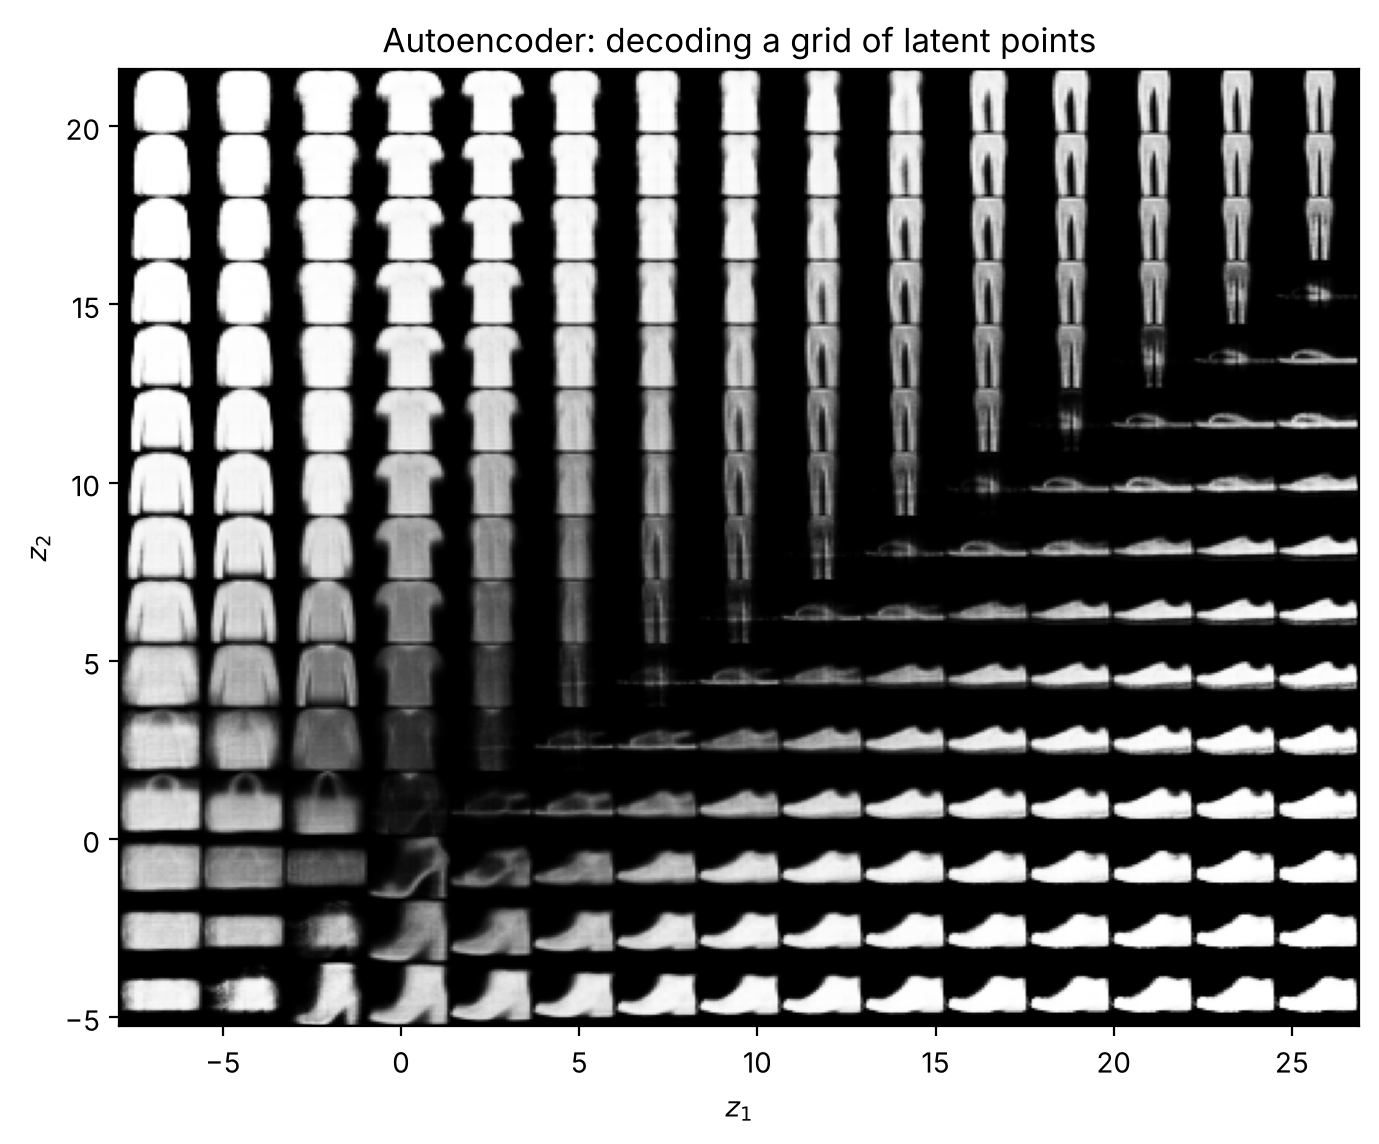

In [15]:
def decode_grid(decoder, z1_range, z2_range, n=15, title=""):
    # Decodes an n x n grid of latent points and tiles the images into one picture
    z1 = np.linspace(*z1_range, n)
    z2 = np.linspace(*z2_range, n)[::-1]   # top row = largest z2, like a normal plot
    grid = np.array([[a, b] for b in z2 for a in z1], dtype=np.float32)
    with torch.inference_mode():
        imgs = decoder(torch.tensor(grid).to(device)).cpu().squeeze(1)
    canvas = imgs.view(n, n, 28, 28).permute(0, 2, 1, 3).reshape(n * 28, n * 28)
    plt.figure(figsize=(8, 8))
    plt.imshow(canvas, cmap="gray", extent=[z1_range[0], z1_range[1], z2_range[0], z2_range[1]])
    plt.xlabel("$z_1$")
    plt.ylabel("$z_2$")
    plt.title(title)
    plt.show()

# Cover the middle 98% of the codes in each direction
lo, hi = np.percentile(ae_codes, [1, 99], axis=0)
decode_grid(ae_2d.decoder, (lo[0], hi[0]), (lo[1], hi[1]),
            title="Autoencoder: decoding a grid of latent points")

Each tile is the decoder's image for one point on the grid, and nearby points give similar images. Walking along the top, long-sleeved tops gradually turn into T-shirts, then dresses, then trousers. Along the bottom, bags turn into ankle boots and then sneakers.

But look at the **dark diagonal band** running from around $(5, 5)$ to $(25, 15)$. Those tiles are almost black, or show faint ghostly outlines of shoes and trousers. That's the empty region between the trouser streak and the footwear band in the scatter plot. The decoder never saw a real code there during training, so it has no idea what to draw.

### Sampling random points

A generative model should let us generate **at random**: pick a random code, decode it, get a new image. But random from *what* distribution? The autoencoder's codes are scattered in an irregular shape. The best we can do is guess: let's draw random points from a normal distribution with the same mean and spread as the real codes.

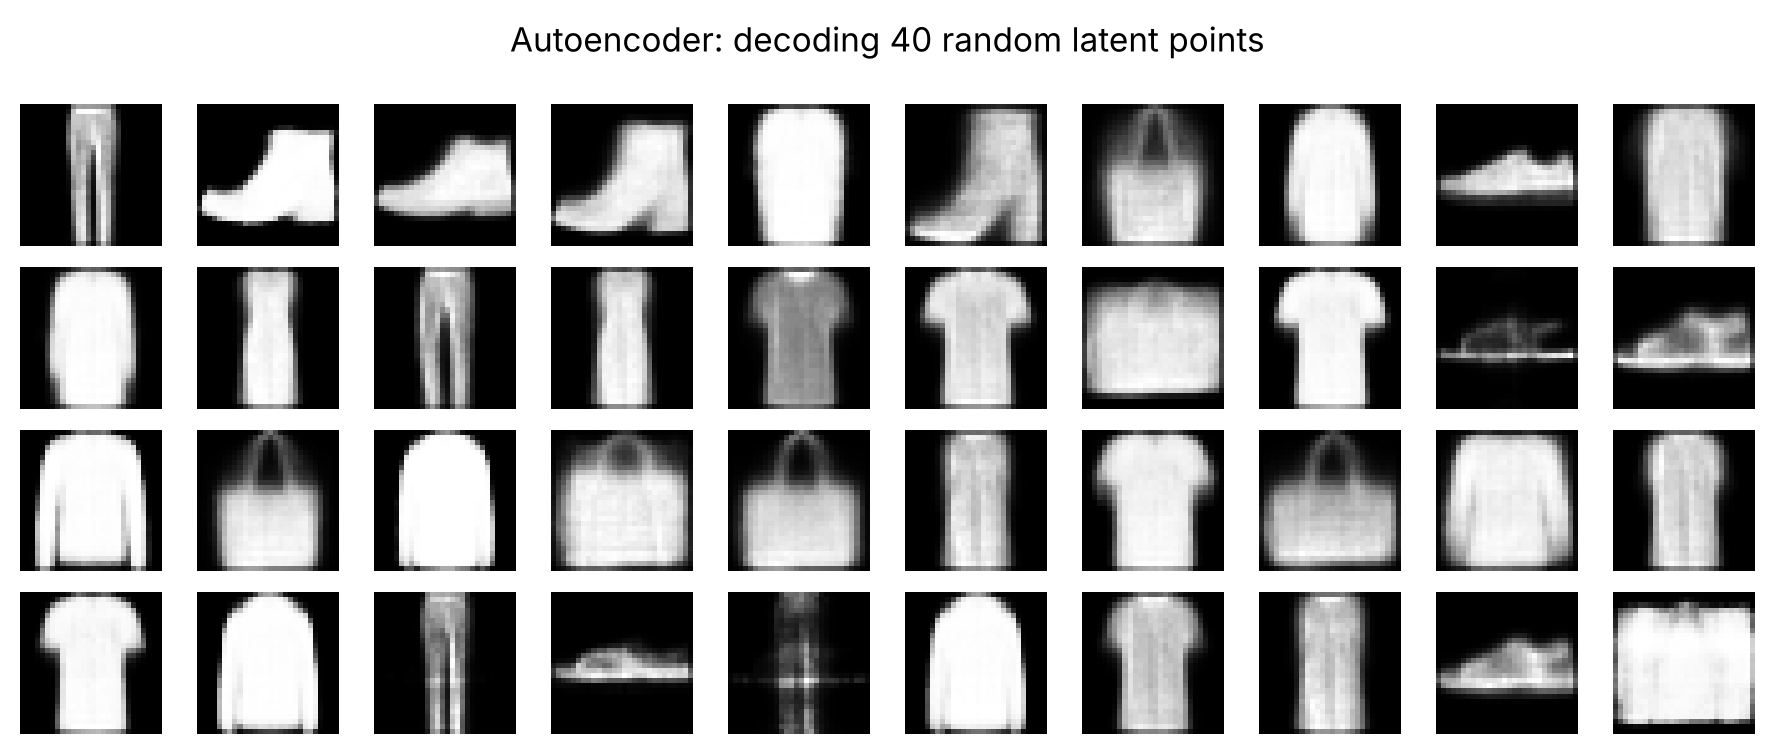

In [16]:
def show_samples(images, title, n_rows=4):
    n_cols = len(images) // n_rows
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9, n_rows * 0.95))
    for ax, img in zip(axes.flat, images):
        ax.imshow(img.squeeze().cpu(), cmap="gray")
        ax.axis(False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

torch.manual_seed(42)
code_mean = torch.tensor(ae_codes.mean(axis=0))
code_std = torch.tensor(ae_codes.std(axis=0))
z_random = code_mean + code_std * torch.randn(40, 2)     # random points with the same mean and spread

with torch.inference_mode():
    ae_samples = ae_2d.decoder(z_random.to(device))

show_samples(ae_samples, "Autoencoder: decoding 40 random latent points")

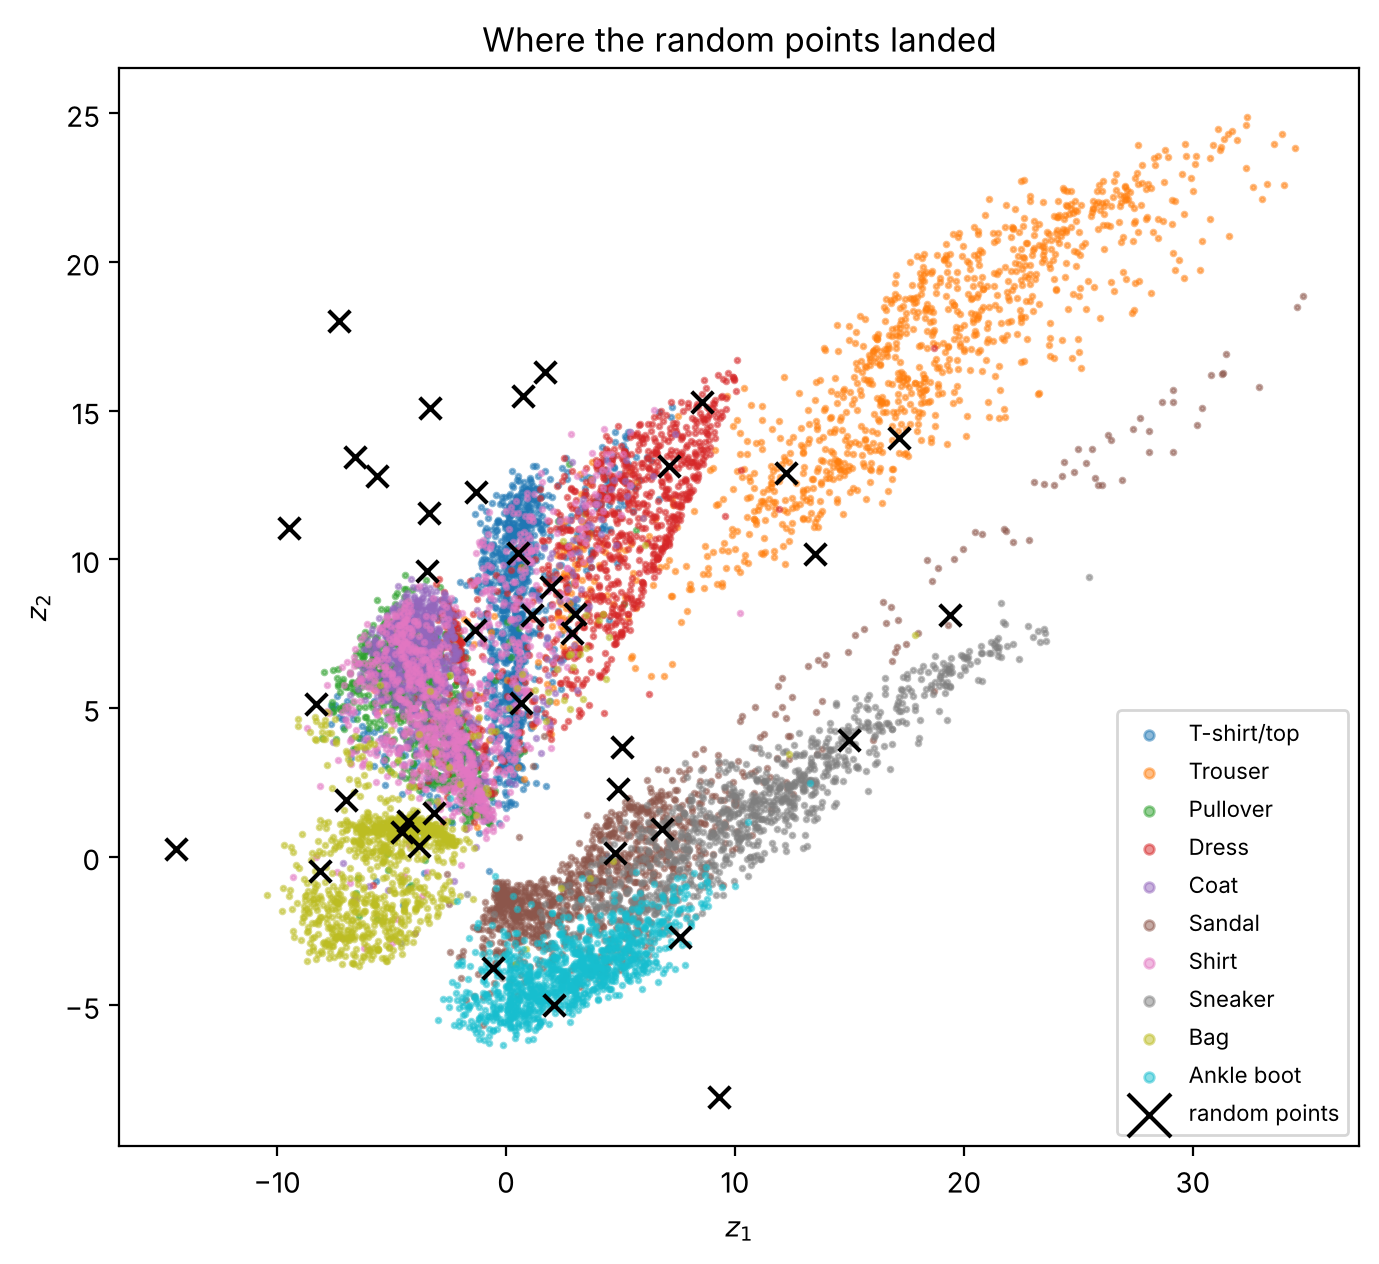

In [17]:
fig, ax = plt.subplots(figsize=(8, 7))
plot_latent(ae_codes, val_labels, "Where the random points landed", ax=ax)
ax.scatter(z_random[:, 0], z_random[:, 1], marker="x", s=60, color="black", label="random points")
ax.legend(markerscale=2, fontsize=8)
plt.show()

Most of the samples are recognizable, so the decoder is more forgiving than you might expect. But look at the failures: a few **featureless white blobs**, one image that's mostly **noise**, and some faint, half-formed shoes.

The second plot shows why. Many random points land in **empty space**, especially the upper left, where no real image has its code. The decoder makes something up there, usually a vague blob.

There's a deeper problem too: to choose these points at all, we had to **look at the real codes** to get their mean and spread. The real codes form long streaks, nothing like a normal distribution, so a normal "blob" covers lots of empty space while barely reaching the far ends of the streaks. A plain autoencoder gives us no principled way to pick a random code. That's the problem a VAE solves.

## Variational Autoencoders (VAEs)

A **variational autoencoder** (Kingma & Welling, 2013) changes two things so that the latent space has no holes and has a known shape we can sample from.

### Change 1: encode to a *region*, not a point

Instead of mapping each image to a single point, the encoder outputs a small **normal distribution**: a mean $\mu$ (where the region is centered) and a standard deviation $\sigma$ (how wide it is). During training, we **sample** a random code $z$ from that region and decode it:

$$z = \mu + \sigma \cdot \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 1)$$

So the same image gets a slightly different code every time it's seen. The decoder has to rebuild the image from *anywhere* in its region, not just one exact point. That forces nearby codes to decode to similar images, which fills in the gaps.

Writing the sample as $\mu + \sigma \cdot \varepsilon$ (rather than "pick a random number") is called the **reparameterization trick**. The randomness is all in $\varepsilon$, so gradients can still flow back through $\mu$ and $\sigma$ to the encoder.

In practice the encoder outputs $\log \sigma^2$ (the "log-variance") instead of $\sigma$, because a log can be any number while $\sigma$ must be positive. Then $\sigma = e^{\frac{1}{2}\log\sigma^2}$.

### Change 2: keep the regions near the origin

On its own, change 1 isn't enough: the encoder could make every region tiny and spread them far apart, which is just a plain autoencoder again. So a VAE adds a second term to the loss, the **KL divergence**, which measures how different each image's region is from a standard normal distribution $\mathcal{N}(0, 1)$:

$$\text{KL} = -\frac{1}{2}\sum_{j} \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

It's zero when $\mu = 0$ and $\sigma = 1$, and grows as the region moves away from the origin or shrinks. The full VAE loss is:

$$\text{loss} = \underbrace{\text{reconstruction loss}}_{\text{rebuild the image well}} + \underbrace{\text{KL}}_{\text{keep codes close to } \mathcal{N}(0,1)}$$

These two terms pull against each other. Reconstruction wants every image to have its own precise, separate code. KL wants every code to look like the same standard normal blob. The compromise is a latent space that is organized *and* packed together around the origin, which is exactly what we need to sample from it: **draw $z$ from $\mathcal{N}(0, 1)$ and decode**.

In [18]:
class VAE(nn.Module):
    def __init__(self, latent_dim: int):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = make_encoder(2 * latent_dim)   # outputs mu AND log-variance
        self.decoder = make_decoder(latent_dim)

    def encode(self, x):
        h = self.encoder(x)
        mu, logvar = h[:, :self.latent_dim], h[:, self.latent_dim:]
        return mu, logvar

    def forward(self, x):
        mu, logvar = self.encode(x)
        sigma = torch.exp(0.5 * logvar)
        eps = torch.randn_like(sigma)
        z = mu + sigma * eps           # reparameterization trick
        return self.decoder(z), mu, logvar


def vae_loss(model, X):
    X_hat, mu, logvar = model(X)
    recon = reconstruction_loss(X_hat, X)
    kl = -0.5 * torch.sum(1 + logvar - mu**2 - logvar.exp()) / len(X)
    return recon + kl, {"recon": recon.item(), "kl": kl.item()}

The encoder and decoder are the same networks as before; the encoder just outputs twice as many numbers. Let's train a VAE with a 2D latent space:

In [19]:
torch.manual_seed(42)
vae_2d = VAE(latent_dim=2).to(device)
optimizer = torch.optim.Adam(vae_2d.parameters(), lr=0.001)

start = time.time()
vae_2d_history = fit(vae_2d, train_dataloader, val_dataloader, vae_loss, optimizer, epochs=15)
print(f"\nTraining time: {(time.time() - start) / 60:.1f} min")

Epoch  0 | recon: train 295.76, val 268.15 | kl: train 6.48, val 6.43


Epoch  1 | recon: train 264.52, val 262.61 | kl: train 6.40, val 6.42


Epoch  2 | recon: train 261.26, val 260.34 | kl: train 6.26, val 6.40


Epoch  3 | recon: train 259.29, val 259.56 | kl: train 6.20, val 6.34


Epoch  4 | recon: train 257.93, val 257.86 | kl: train 6.21, val 6.31


Epoch  5 | recon: train 256.90, val 256.74 | kl: train 6.22, val 6.45


... (5 outputs left out)

Epoch 11 | recon: train 253.45, val 253.89 | kl: train 6.33, val 6.43


Epoch 12 | recon: train 253.01, val 253.60 | kl: train 6.33, val 6.24


Epoch 13 | recon: train 252.80, val 253.17 | kl: train 6.33, val 6.54


Epoch 14 | recon: train 252.57, val 253.88 | kl: train 6.34, val 6.20

Training time: 1.3 min


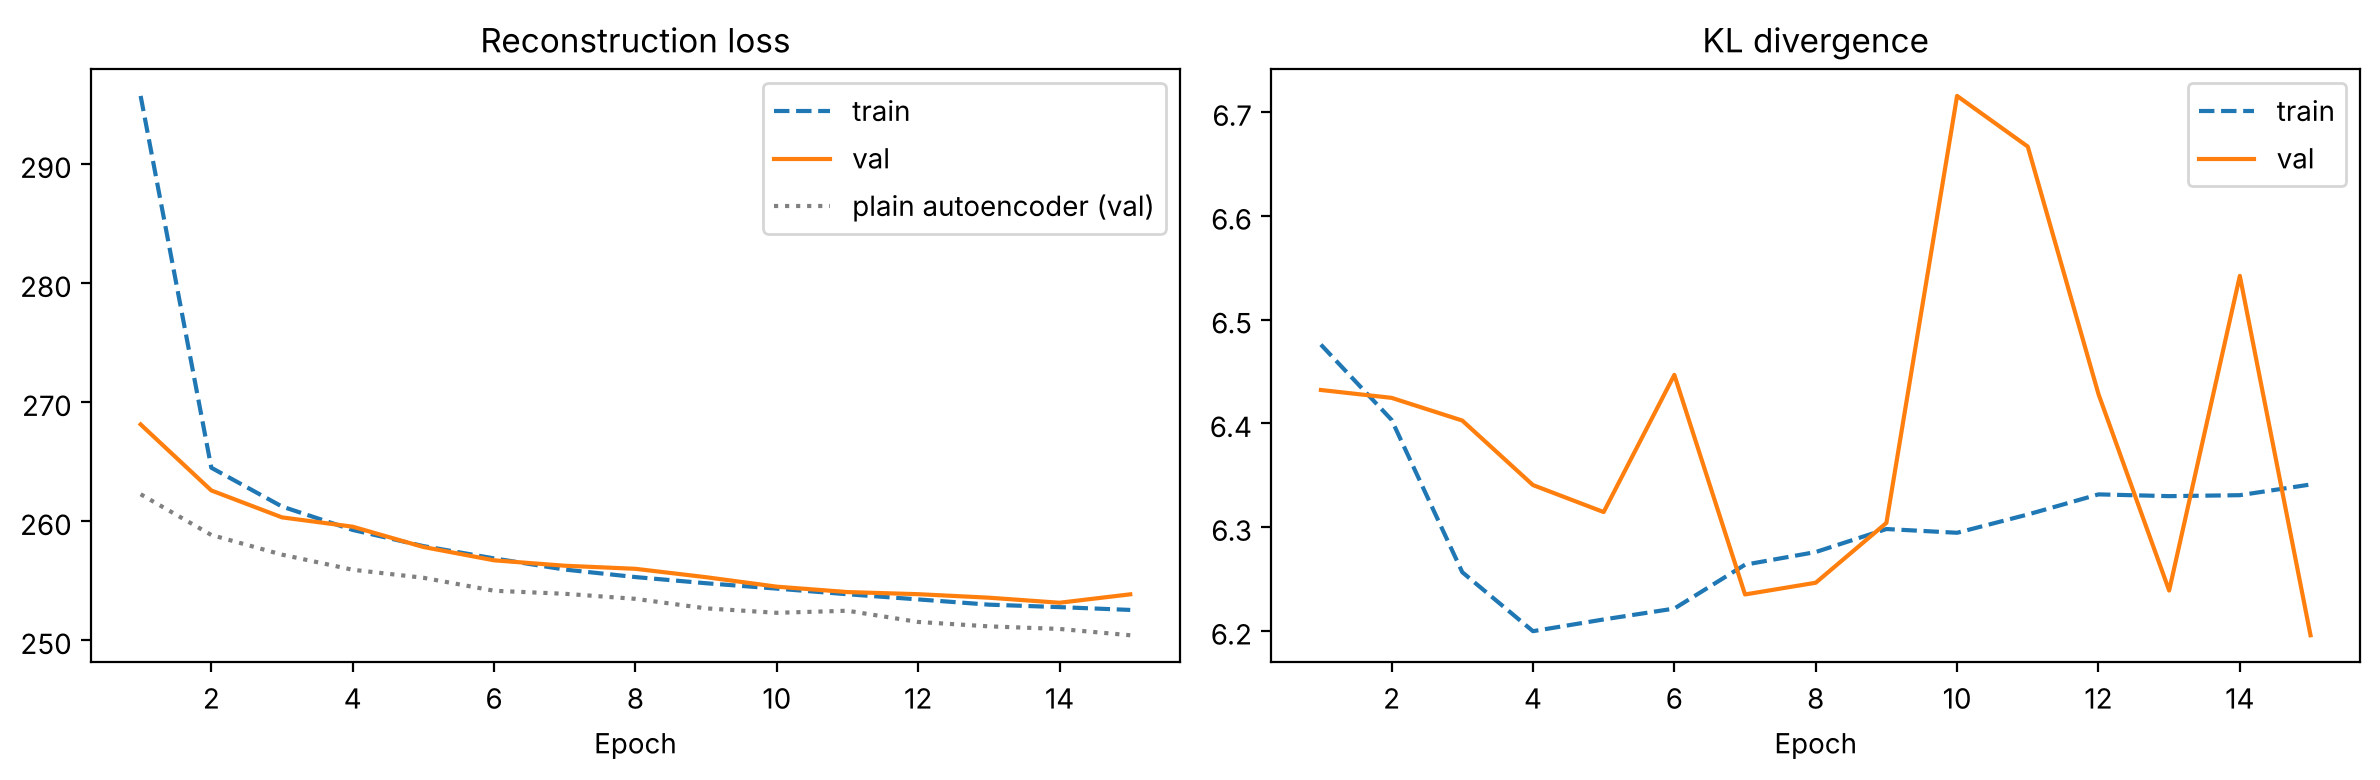

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(vae_2d_history["train_recon"]) + 1)
for ax, key, title in [(axes[0], "recon", "Reconstruction loss"), (axes[1], "kl", "KL divergence")]:
    ax.plot(epochs, vae_2d_history[f"train_{key}"], "--", label="train")
    ax.plot(epochs, vae_2d_history[f"val_{key}"], "-", label="val")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend()
axes[0].plot(epochs, ae_2d_history["val_recon"], ":", color="gray", label="plain autoencoder (val)")
axes[0].legend()
plt.tight_layout()
plt.show()

- The **reconstruction loss** ends slightly worse than the plain autoencoder's (about 254 vs. 250). That's the price of the KL term and of the randomness: the VAE gives up a little accuracy to keep its latent space organized.
- The **KL divergence** stays roughly constant around 6.2-6.7 (note the narrow y-axis). The model doesn't let its codes drift away from $\mathcal{N}(0, 1)$, and it improves reconstruction within that budget.
- The validation KL looks jumpy only because the y-axis is zoomed in. It's measured once at the end of each epoch, while the training value is averaged over the whole epoch.

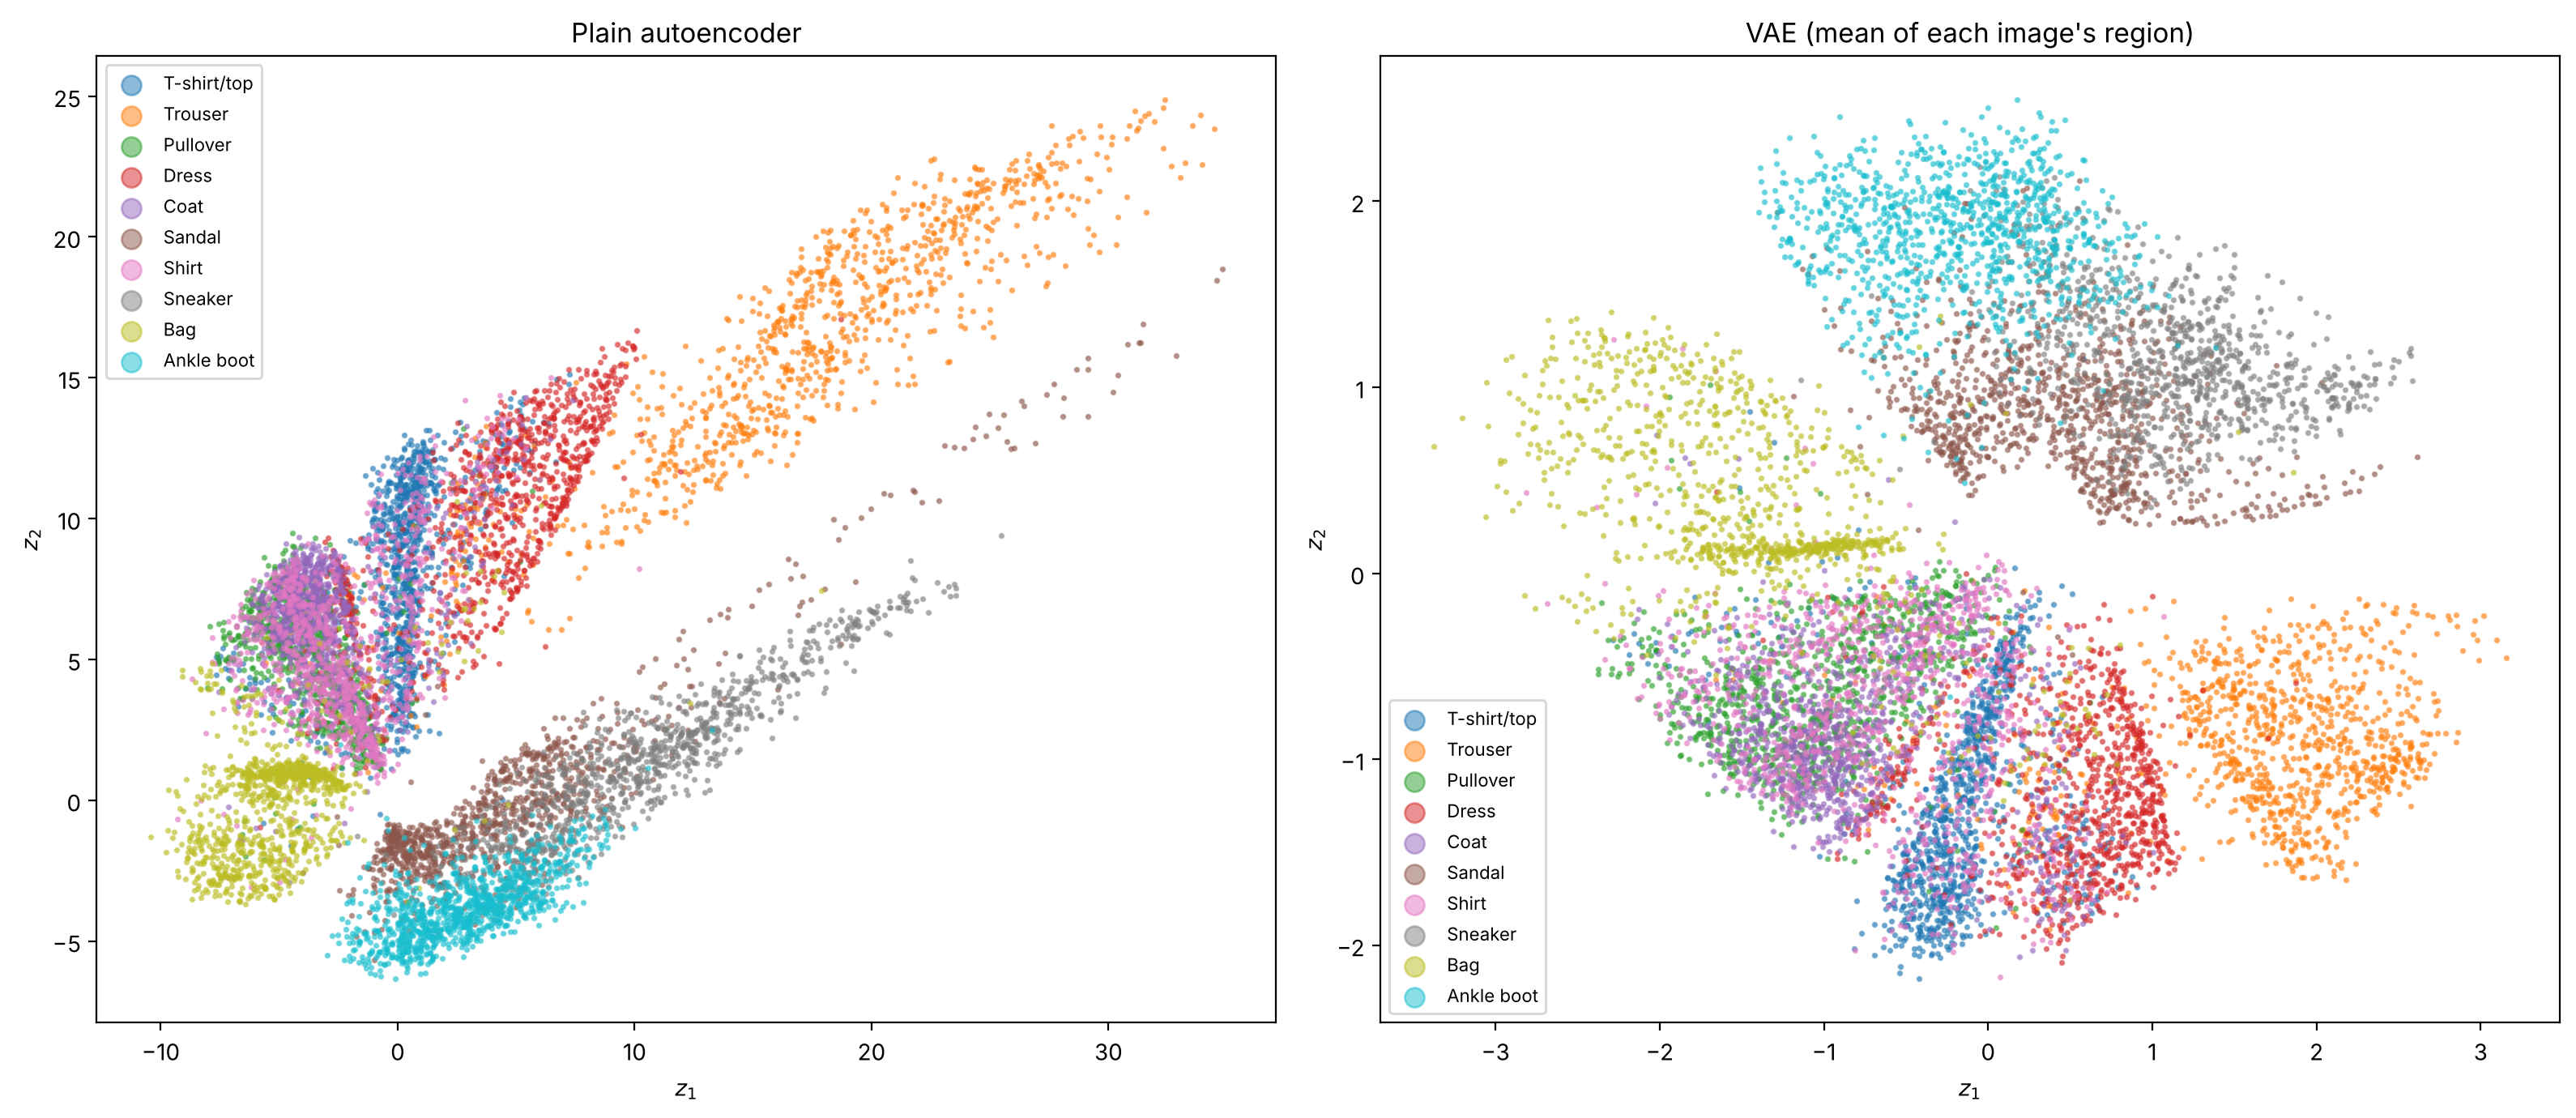

In [21]:
vae_2d.eval()
vae_codes, _ = encode_dataset(lambda X: vae_2d.encode(X)[0], val_dataloader)   # use the mean, mu

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_latent(ae_codes, val_labels, "Plain autoencoder", ax=axes[0])
plot_latent(vae_codes, val_labels, "VAE (mean of each image's region)", ax=axes[1])
plt.tight_layout()
plt.show()

Compare the axes first. The autoencoder's codes stretch from about $-10$ to $35$; the VAE's are packed into roughly $-3$ to $3$, in a rounded blob centered at the origin, close to the $\mathcal{N}(0, 1)$ shape the KL term asks for.

The organization is the same: footwear together, bags together, trousers on their own, and the look-alike tops overlapping. But now the classes are **packed next to each other** instead of being spread along streaks with large empty spaces between them. Not every gap is gone; there's still a visible seam between the bags and footwear on top and the tops and trousers below.

## Sampling New Images

Now generating is easy, and principled: the KL term trained the codes to look like $\mathcal{N}(0, 1)$, so we draw random codes from $\mathcal{N}(0, 1)$ and decode them. Let's compare with the plain autoencoder's samples from before.

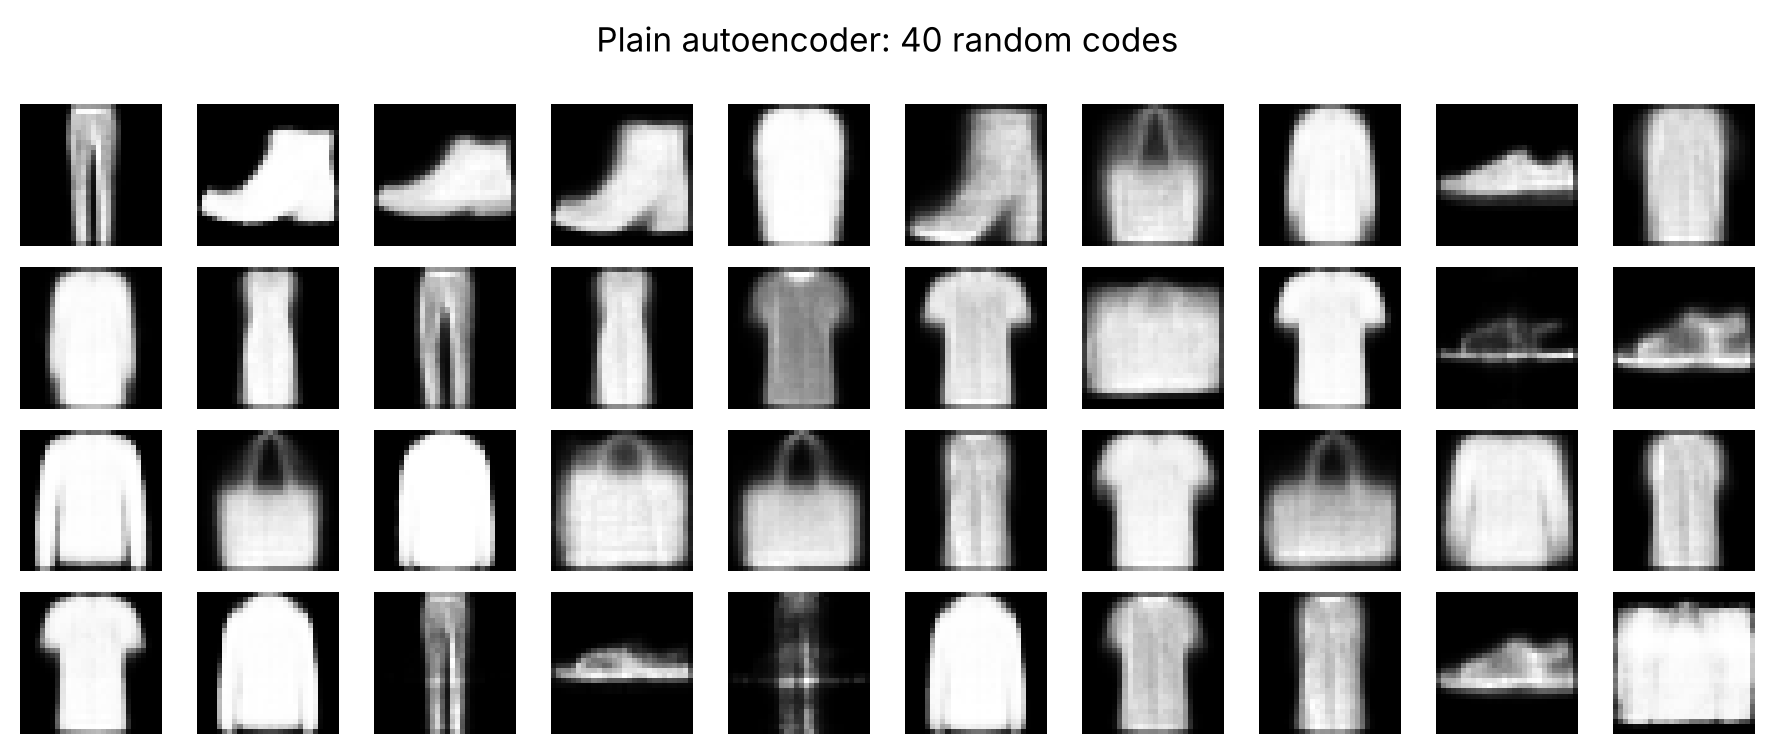

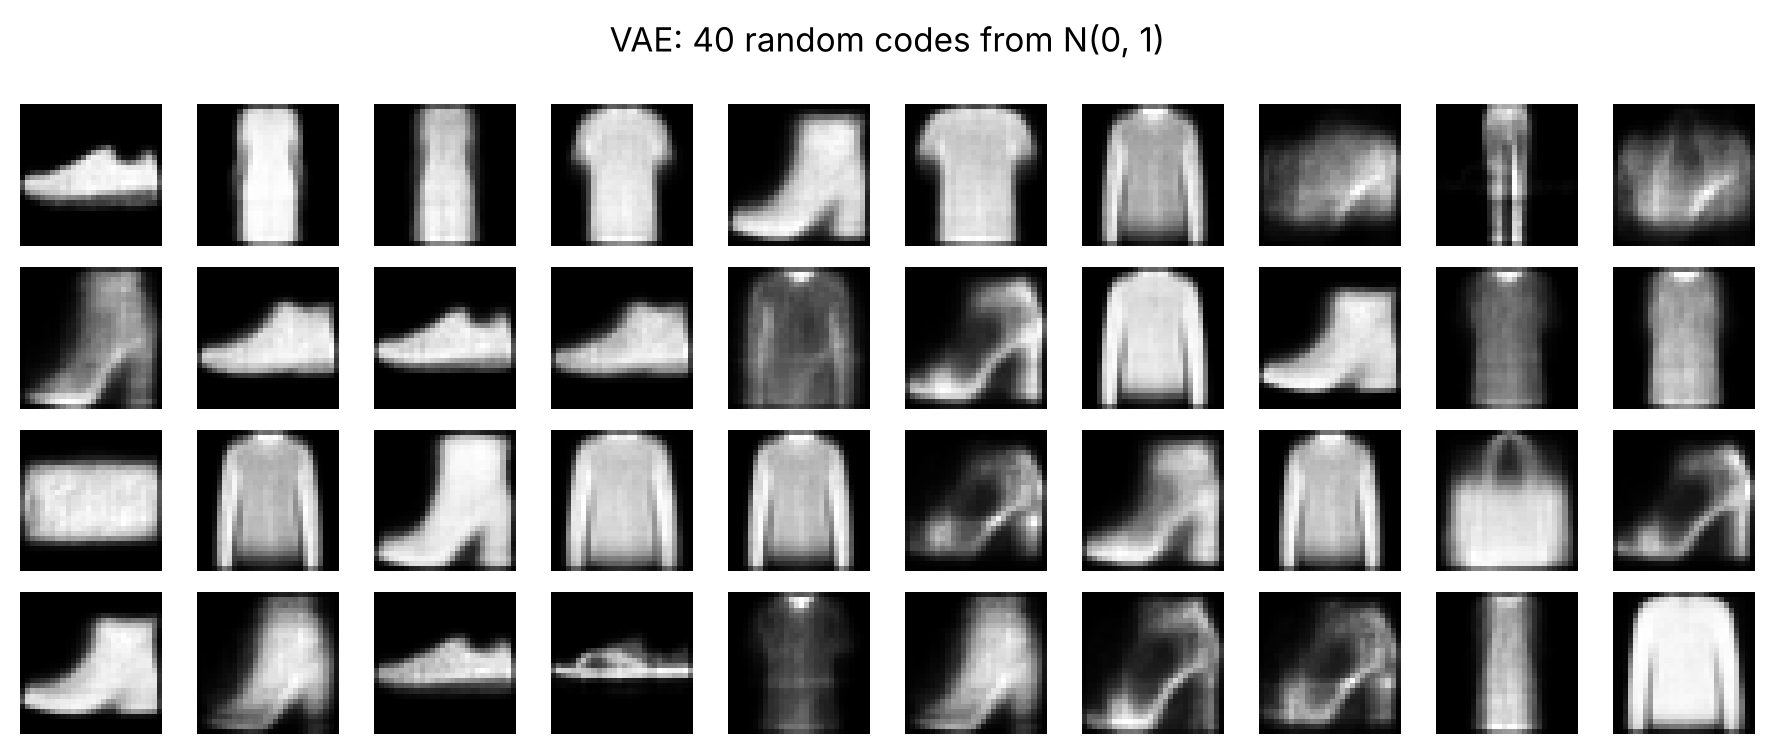

In [22]:
torch.manual_seed(42)
z_random = torch.randn(40, 2)

with torch.inference_mode():
    vae_samples = vae_2d.decoder(z_random.to(device))

show_samples(ae_samples, "Plain autoencoder: 40 random codes")
show_samples(vae_samples, "VAE: 40 random codes from N(0, 1)")

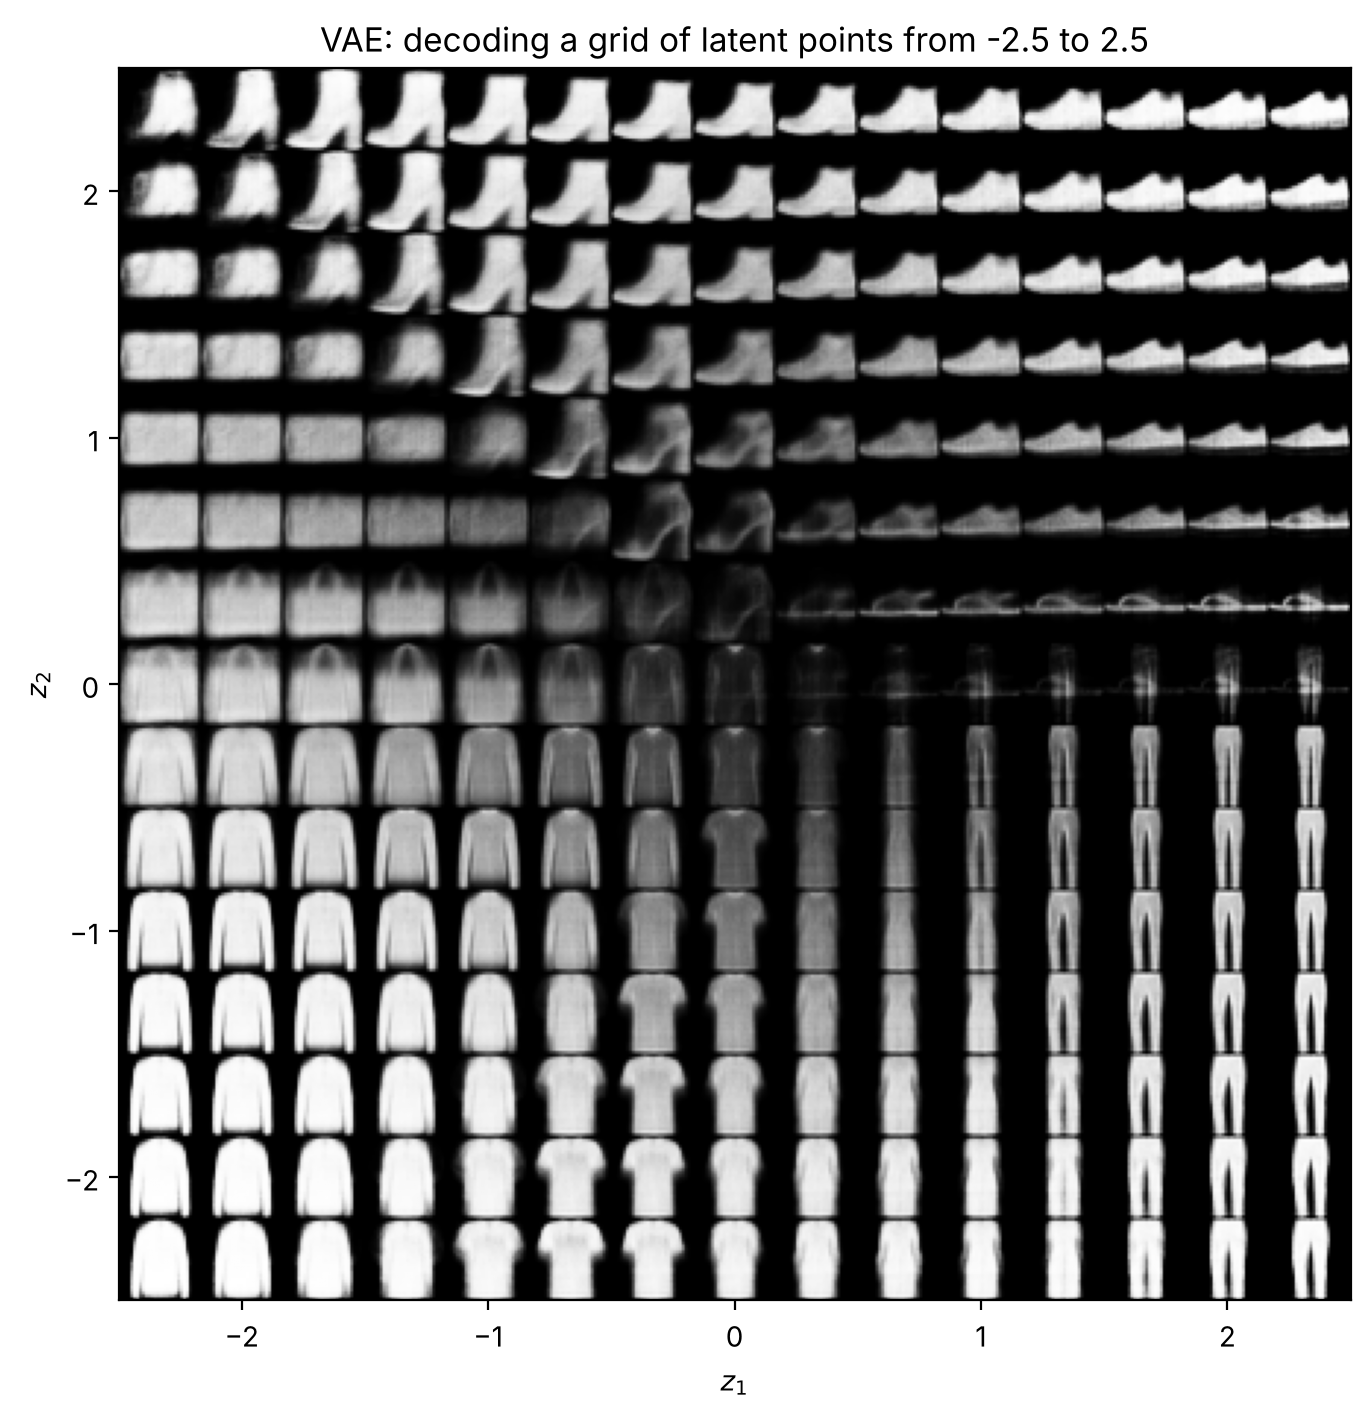

In [23]:
decode_grid(vae_2d.decoder, (-2.5, 2.5), (-2.5, 2.5),
            title="VAE: decoding a grid of latent points from -2.5 to 2.5")

Side by side, the samples look **similar**: both sets are mostly recognizable, with some failures. The VAE's failures are mostly ghostly blends of a boot and a sandal (sandals, with their thin straps, are the hardest items to draw). The autoencoder's failures were featureless blobs and noise.

The grid shows the real difference. Every tile from $-2.5$ to $2.5$ decodes to an item or a smooth blend between neighboring items: boots turn into sneakers along the top, bags into tops along the left side, tops into trousers along the bottom. There's no large dark region like the autoencoder's. The only weak spot is a faint strip on the right around $z_2 = 0$, between sneakers and trousers, matching the seam in the scatter plot.

And we knew where to look **without peeking at the real codes**: the KL term trained the codes to fit $\mathcal{N}(0, 1)$, so that's where we sample.

### Measuring the holes

Looking at 40 samples is a judgment call. We can also measure it: draw 2,000 random codes the way we did for each model, and for each one, check how far it is from the **nearest real code**. If a random code is much farther from every real image than real images usually are from each other, it's sitting in a hole, and its decoded image is something the model never learned to make.

We use `NearestNeighbors` from scikit-learn, and call a point "in a hole" if its nearest real code is more than 3 times the typical distance between neighboring real codes. (Dividing by the typical distance lets us compare the two models, even though their latent spaces have very different scales.)

In [24]:
from sklearn.neighbors import NearestNeighbors

def percent_in_holes(real_codes, random_codes, factor=3):
    nn_finder = NearestNeighbors(n_neighbors=2).fit(real_codes)
    # Typical distance from a real code to its nearest *other* real code
    typical = np.median(nn_finder.kneighbors(real_codes)[0][:, 1])
    # Distance from each random code to its nearest real code
    dist = nn_finder.kneighbors(random_codes, n_neighbors=1)[0][:, 0]
    return (dist > factor * typical).mean() * 100

torch.manual_seed(0)
ae_random = (code_mean + code_std * torch.randn(2000, 2)).numpy()   # needed the real codes to choose these!
vae_random = torch.randn(2000, 2).numpy()                           # just N(0, 1)

pd.DataFrame({"% of random codes in a hole": {
    "Plain autoencoder": percent_in_holes(ae_codes, ae_random),
    "VAE": percent_in_holes(vae_codes, vae_random),
}}).round(1)

,% of random codes in a hole
Plain autoencoder,50.3
VAE,26.2


About **half** of the plain autoencoder's random codes land in holes, compared with about **a quarter** for the VAE. That's even though we gave the autoencoder its best possible chance, by choosing its random codes using the real codes' mean and spread.

The VAE doesn't get to zero. The KL term pulls *each image's* region toward $\mathcal{N}(0, 1)$, but it doesn't guarantee that *all the codes together* fill $\mathcal{N}(0, 1)$ evenly. That's why we could still see seams in the scatter plot.

### More latent dimensions?

With only 2 latent dimensions, the VAE has to describe a whole outfit with 2 numbers, so samples are blurry. For the plain autoencoder, going from 2 to 16 dimensions made reconstructions much sharper. Let's see if the same helps the VAE's samples. We can't plot a 16D latent space, but sampling works exactly the same way.

In [25]:
torch.manual_seed(42)
vae_16d = VAE(latent_dim=16).to(device)
optimizer = torch.optim.Adam(vae_16d.parameters(), lr=0.001)
vae_16d_history = fit(vae_16d, train_dataloader, val_dataloader, vae_loss, optimizer,
                      epochs=15, print_every=3)

Epoch  0 | recon: train 296.41, val 259.21 | kl: train 10.29, val 12.39


Epoch  3 | recon: train 239.47, val 238.59 | kl: train 11.56, val 11.59


Epoch  6 | recon: train 233.50, val 233.63 | kl: train 12.10, val 12.13


Epoch  9 | recon: train 230.92, val 231.41 | kl: train 12.43, val 12.26


Epoch 12 | recon: train 229.43, val 229.93 | kl: train 12.62, val 12.72


Epoch 14 | recon: train 228.78, val 229.50 | kl: train 12.70, val 12.71


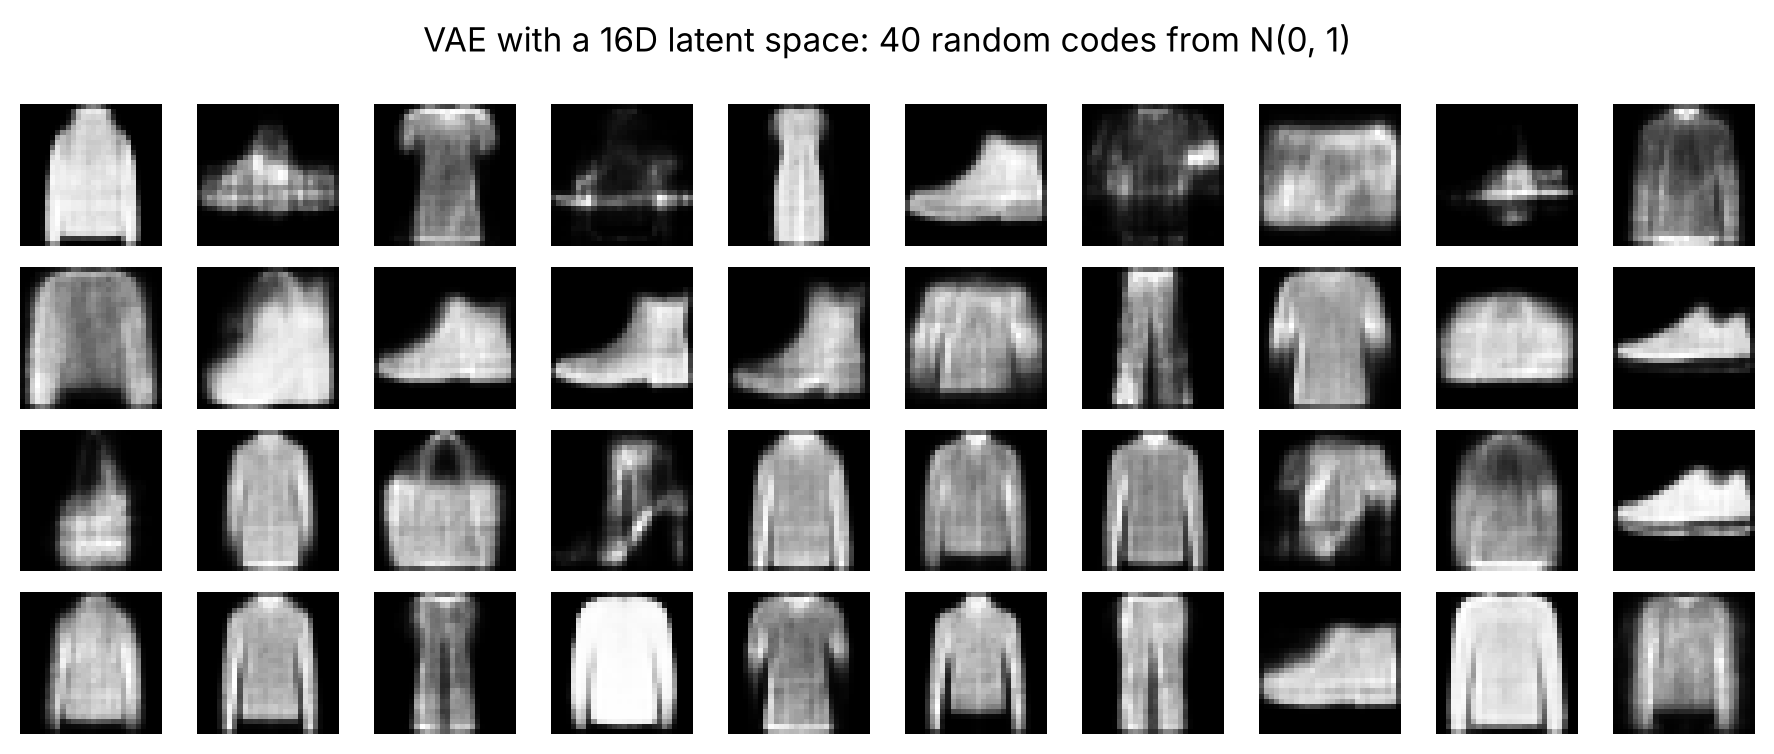

In [26]:
torch.manual_seed(42)
with torch.inference_mode():
    vae_16d_samples = vae_16d.decoder(torch.randn(40, 16).to(device))

show_samples(vae_16d_samples, "VAE with a 16D latent space: 40 random codes from N(0, 1)")

The 16D VAE reconstructs images much better than the 2D one (validation reconstruction loss of about 230, vs. 254). But its **samples aren't sharper**. A few tops have more texture, but there are *more* failures: noisy ghosts and half-formed shapes.

The reason is the same hole problem, made worse by more dimensions. In 2D, the real codes can fill most of the $\mathcal{N}(0, 1)$ blob. In 16D there's vastly more room, so random draws from $\mathcal{N}(0, 1)$ land in between real codes much more often.

This is a real limitation of VAEs, not just of our small model: they reconstruct well, but their samples tend to be blurry, and some fail. It's one of the main reasons people developed the generative models we'll look at next.

## Interpolation

Another way to see that a latent space is meaningful: take two real images, find their codes, and walk in a straight line from one code to the other, decoding along the way. We'll try two pairs: two kinds of shoe, and a shoe and a pair of trousers.

For comparison, we'll also "walk" in **pixel space**, which just fades one image into the other.

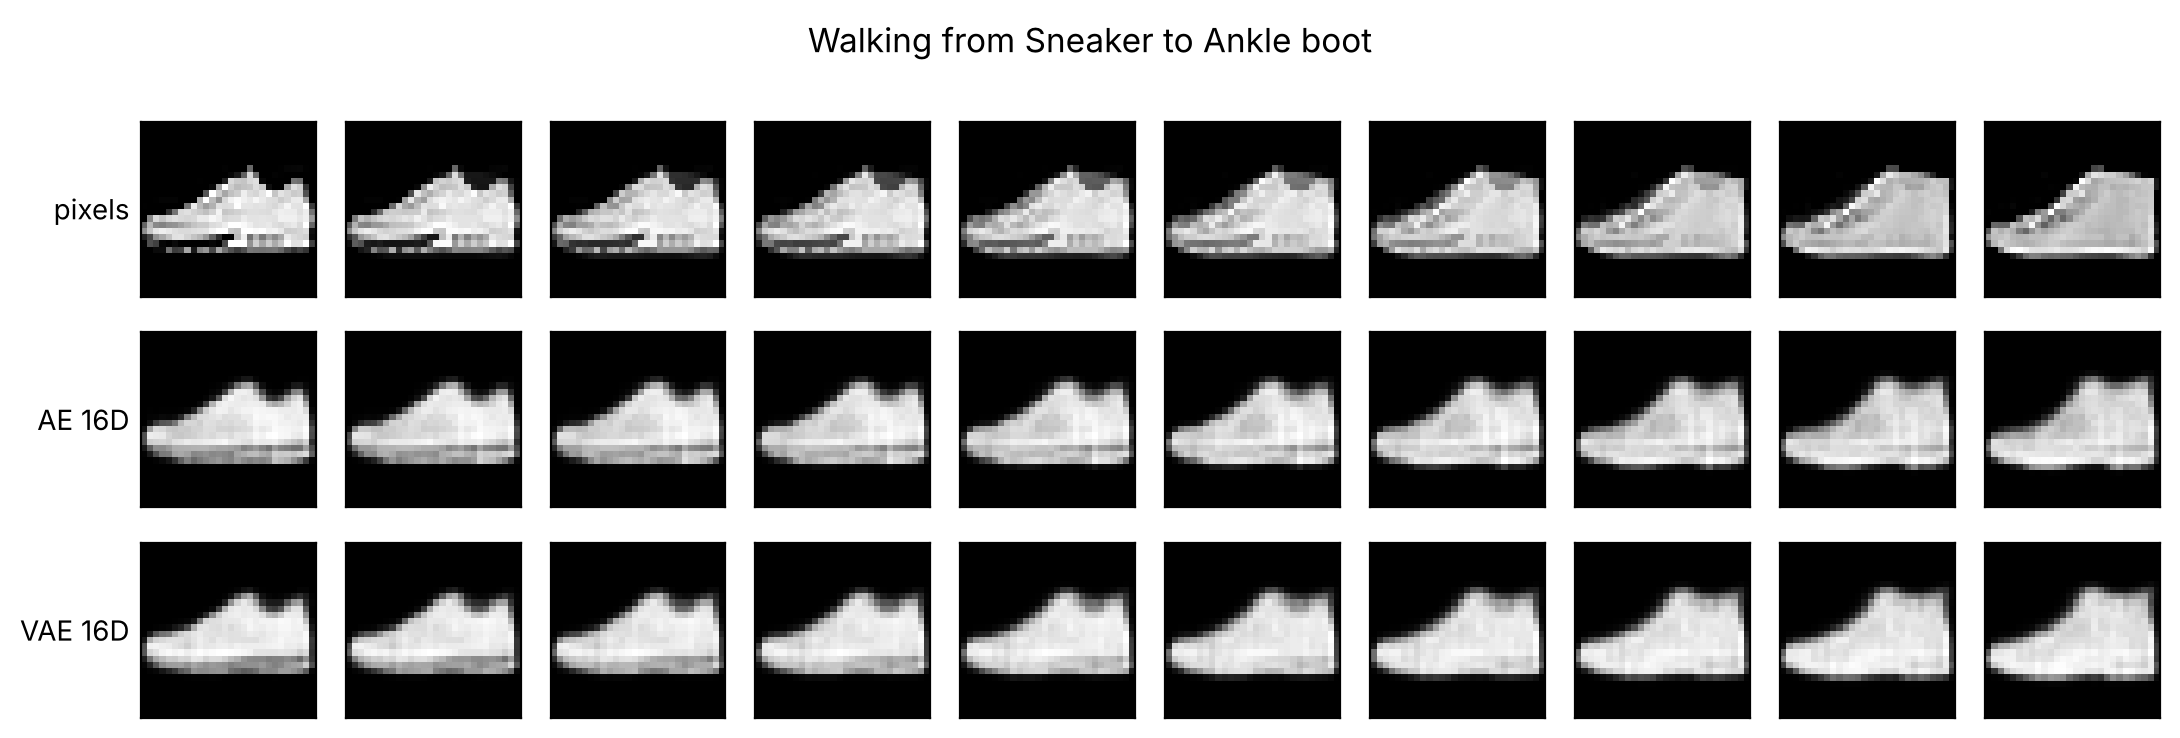

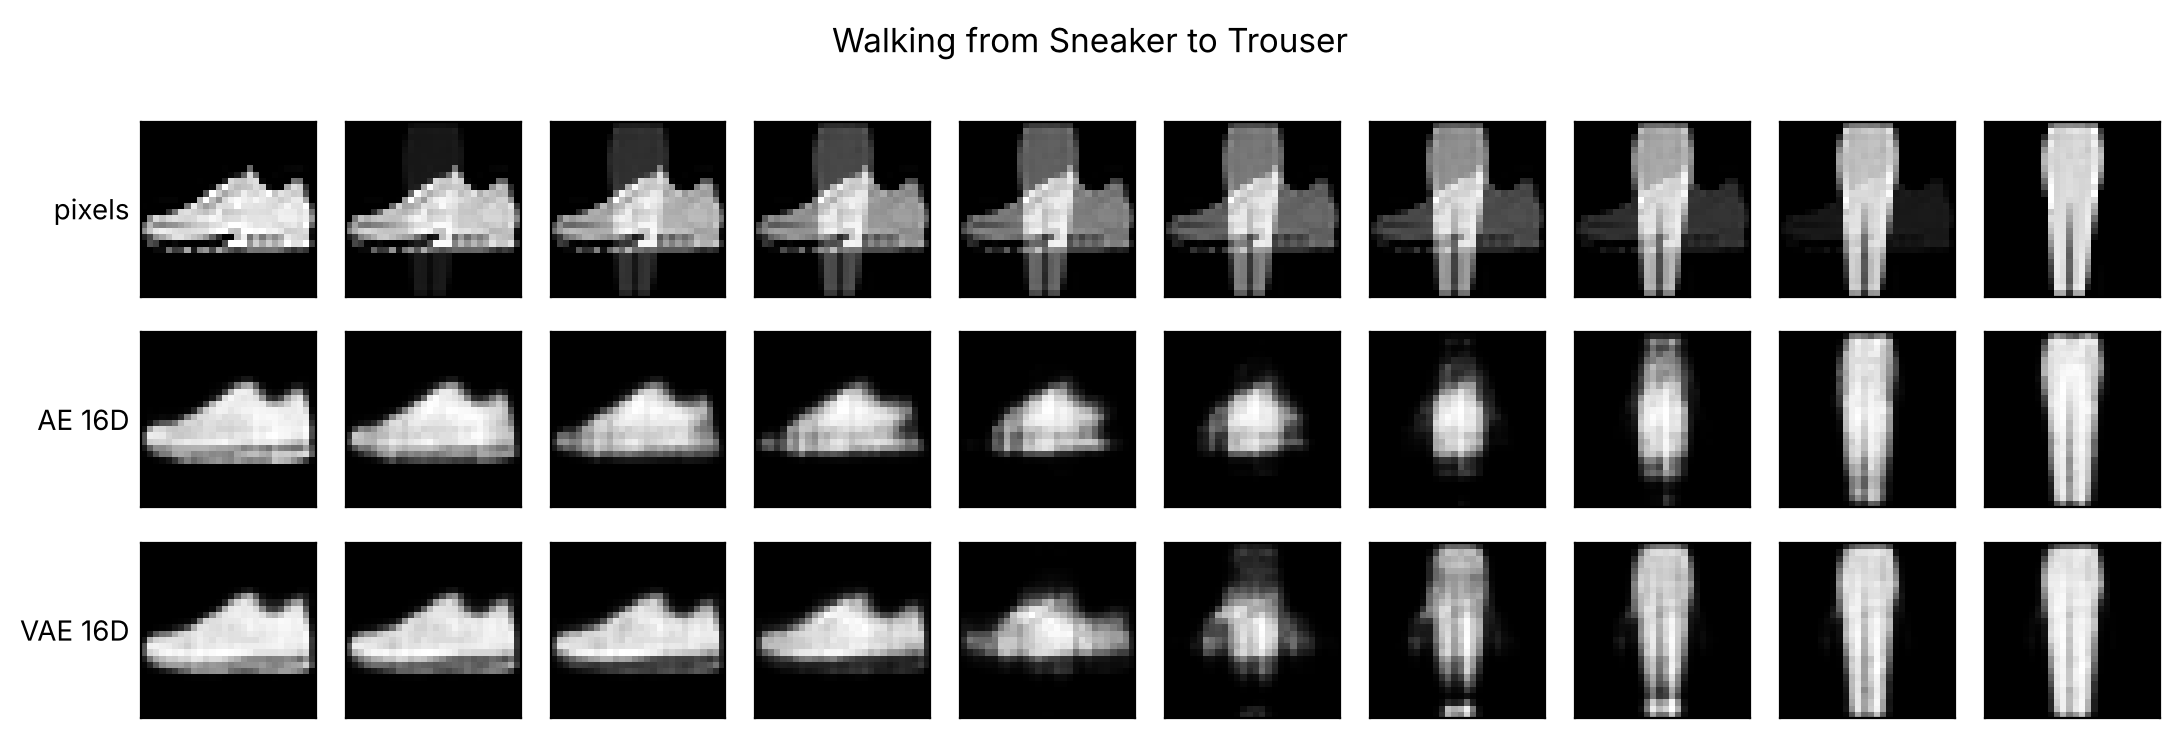

In [27]:
def find_example(class_name, data=val_split):
    # Index of the first validation image of a given class
    k = class_names.index(class_name)
    return next(i for i in range(len(data)) if data[i][1] == k)

def interpolate(class_a, class_b):
    img_a = val_split[find_example(class_a)][0].unsqueeze(0).to(device)
    img_b = val_split[find_example(class_b)][0].unsqueeze(0).to(device)
    steps = torch.linspace(0, 1, 10).to(device)

    with torch.inference_mode():
        # Pixel space: fade from one image to the other
        pixel_path = torch.stack([(1 - t) * img_a[0] + t * img_b[0] for t in steps])

        # Autoencoder latent space
        za, zb = ae_16d.encoder(img_a), ae_16d.encoder(img_b)
        ae_path = ae_16d.decoder(torch.cat([(1 - t) * za + t * zb for t in steps]))

        # VAE latent space (use the means)
        ma, mb = vae_16d.encode(img_a)[0], vae_16d.encode(img_b)[0]
        vae_path = vae_16d.decoder(torch.cat([(1 - t) * ma + t * mb for t in steps]))

    fig, axes = plt.subplots(3, 10, figsize=(11, 3.8))
    for row, (name, path) in enumerate([("pixels", pixel_path), ("AE 16D", ae_path), ("VAE 16D", vae_path)]):
        for j in range(10):
            axes[row, j].imshow(path[j].squeeze().cpu(), cmap="gray")
            axes[row, j].set_xticks([])
            axes[row, j].set_yticks([])
        axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
    fig.suptitle(f"Walking from {class_a} to {class_b}")
    plt.tight_layout()
    plt.show()

interpolate("Sneaker", "Ankle boot")
interpolate("Sneaker", "Trouser")

**Sneaker to ankle boot.** Fading the pixels gives two shoes **superimposed**, with ghostly double outlines halfway through: an image no camera would ever take. Walking through either latent space instead **morphs the shape**: the shoe gradually gets taller, and every frame is a plausible shoe. The latent space has learned that "sneaker" and "ankle boot" are related, with real shoes in between.

**Sneaker to trousers.** There's no natural in-between of a shoe and a pair of pants, so both paths have to cross a region where no real items exist. The autoencoder passes through about four shapeless blobs before the trousers appear; the VAE passes through about two. Fewer holes, cleaner path, consistent with what we measured above.

## Denoising Autoencoders

One more variation, because it leads straight into next lecture. A **denoising autoencoder** is trained to take a **noisy** image as input and output the **clean** image. Everything is the same as before, except that we add random noise to the input inside the loss function:

In [28]:
NOISE_STD = 0.5

def add_noise(X, noise_std=NOISE_STD):
    return (X + noise_std * torch.randn_like(X)).clamp(0, 1)


def denoising_loss(model, X):
    X_hat = model(add_noise(X))               # input: noisy image
    loss = reconstruction_loss(X_hat, X)      # target: the clean image
    return loss, {"recon": loss.item()}


torch.manual_seed(42)
denoiser = Autoencoder(latent_dim=32).to(device)
optimizer = torch.optim.Adam(denoiser.parameters(), lr=0.001)
denoiser_history = fit(denoiser, train_dataloader, val_dataloader, denoising_loss, optimizer,
                       epochs=10, print_every=3)

Epoch  0 | recon: train 306.82, val 262.04


Epoch  3 | recon: train 243.79, val 243.43


Epoch  6 | recon: train 237.66, val 237.67


Epoch  9 | recon: train 234.87, val 235.02


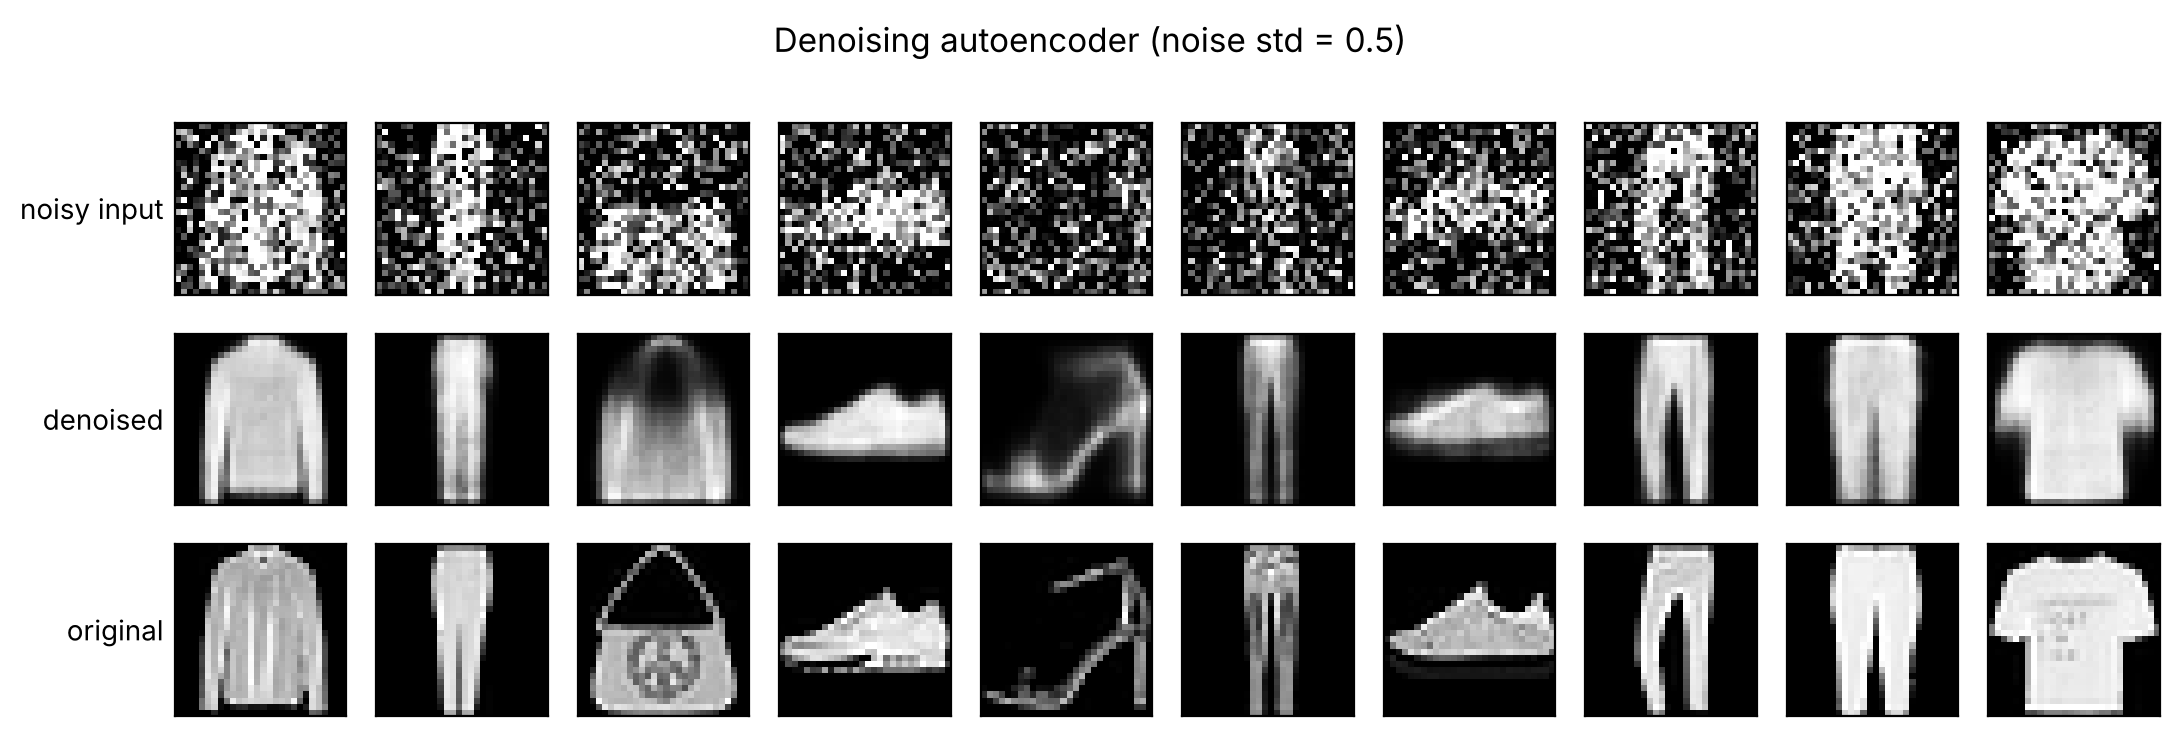

In [29]:
torch.manual_seed(0)
X_noisy = add_noise(X_val[:10])
denoiser.eval()
with torch.inference_mode():
    X_denoised = denoiser(X_noisy)

fig, axes = plt.subplots(3, 10, figsize=(11, 3.8))
for row, (name, imgs) in enumerate([("noisy input", X_noisy), ("denoised", X_denoised), ("original", X_val[:10])]):
    for j in range(10):
        axes[row, j].imshow(imgs[j].squeeze().cpu(), cmap="gray")
        axes[row, j].set_xticks([])
        axes[row, j].set_yticks([])
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
fig.suptitle(f"Denoising autoencoder (noise std = {NOISE_STD})")
plt.tight_layout()
plt.show()

At this noise level, several of the inputs are hard for a *person* to recognize (look at the sandal). The denoiser still recovers the type and shape of all ten items.

Notice what it does **not** recover: the bag's print, the stripes on the long-sleeved top, the text on the T-shirt. The denoiser isn't uncovering the exact original hidden under the noise. It produces a **plausible clean item** consistent with the noisy input, using what it learned about what clothing looks like.

That's the key idea behind **diffusion models**, which power modern image generators. Train a network to remove a little noise, at every noise level from "slightly noisy" to "pure static". Then, to generate, start from **pure random noise** and denoise it step by step. Each step makes the image a little more plausible, until a brand-new image appears. We'll build that next lecture.